# ECE 3715 Mini-Project 2: Continuous Random Variables

In [36]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import gamma as gamma_fn
from scipy.stats import norm            # used to cross-check q_function in Step 6

import mp2lib as L
from mp2lib import (q_function, q_inverse, std_normal_cdf, std_normal_pdf,
                    ks_statistic, ks_two_sample, ks_critical, ks_critical_two_sample,
                    inv_cdf_exponential, inv_cdf_rayleigh, sample_by_inversion,
                    mc_probability, count_exceedances, running_mean_var)

SEED = 300132899
rng = np.random.default_rng(SEED)

# One independent generator per step
(rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8,
 rngA, rngB) = rng.spawn(10)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
T_START = time.time()

## Step 1: From CDF to density

### 1.1 The four distributions

| Distribution | Support | CDF $F(x)$ | pdf $f(x) = F'(x)$ |
|---|---|---|---|
| Uniform $[0,1]$ | $0 \le x \le 1$ | $x$ | $1$ |
| Exponential, rate $\lambda = 1$ | $x \ge 0$ | $1 - e^{-\lambda x}$ | $\lambda e^{-\lambda x}$ |
| Standard Gaussian | $-\infty < x < \infty$ | $\Phi(x) = 1 - Q(x)$ | $\dfrac{1}{\sqrt{2\pi}}e^{-x^2/2}$ |
| Rayleigh, scale $\sigma = 1$ | $x \ge 0$ | $1 - e^{-x^2/2\sigma^2}$ | $\dfrac{x}{\sigma^2}e^{-x^2/2\sigma^2}$ |

Outside the support the CDF is 0 (to the left) or 1 (to the right) and the pdf is 0. The Gaussian CDF has no elementary closed form; it is evaluated here through `q_function`, which Step 6 builds from erfc.

In [2]:
N1 = 100_000
crit1 = ks_critical(N1)

dists = {   # name: (library samples, analytic CDF, analytic pdf, plot range)
    "Uniform [0,1]":   (rng1.random(N1),            L.cdf_uniform,     L.pdf_uniform,     (-0.2, 1.2)),
    "Exponential(1)":  (rng1.exponential(1.0, N1),  L.cdf_exponential, L.pdf_exponential, (0, 8)),
    "Gaussian N(0,1)": (rng1.standard_normal(N1),   std_normal_cdf,    std_normal_pdf,    (-4.5, 4.5)),
    "Rayleigh(1)":     (rng1.rayleigh(1.0, N1),     L.cdf_rayleigh,    L.pdf_rayleigh,    (0, 5)),
}

print(f"KS statistic vs analytic CDF, N = {N1:,}, 95% critical value = {crit1:.4f}")
print(f"{'distribution':<17} {'KS':>8}  result")
ks1 = {}
for name, (x, cdf, pdf, rg) in dists.items():
    ks1[name] = ks_statistic(x, cdf)
    print(f"{name:<17} {ks1[name]:>8.4f}  {'pass (below critical)' if ks1[name] < crit1 else 'FAIL'}")

KS statistic vs analytic CDF, N = 100,000, 95% critical value = 0.0043
distribution            KS  result
Uniform [0,1]       0.0027  pass (below critical)
Exponential(1)      0.0030  pass (below critical)
Gaussian N(0,1)     0.0037  pass (below critical)
Rayleigh(1)         0.0017  pass (below critical)


### Figure 1: Empirical vs. analytic CDFs (top) and densities (bottom)

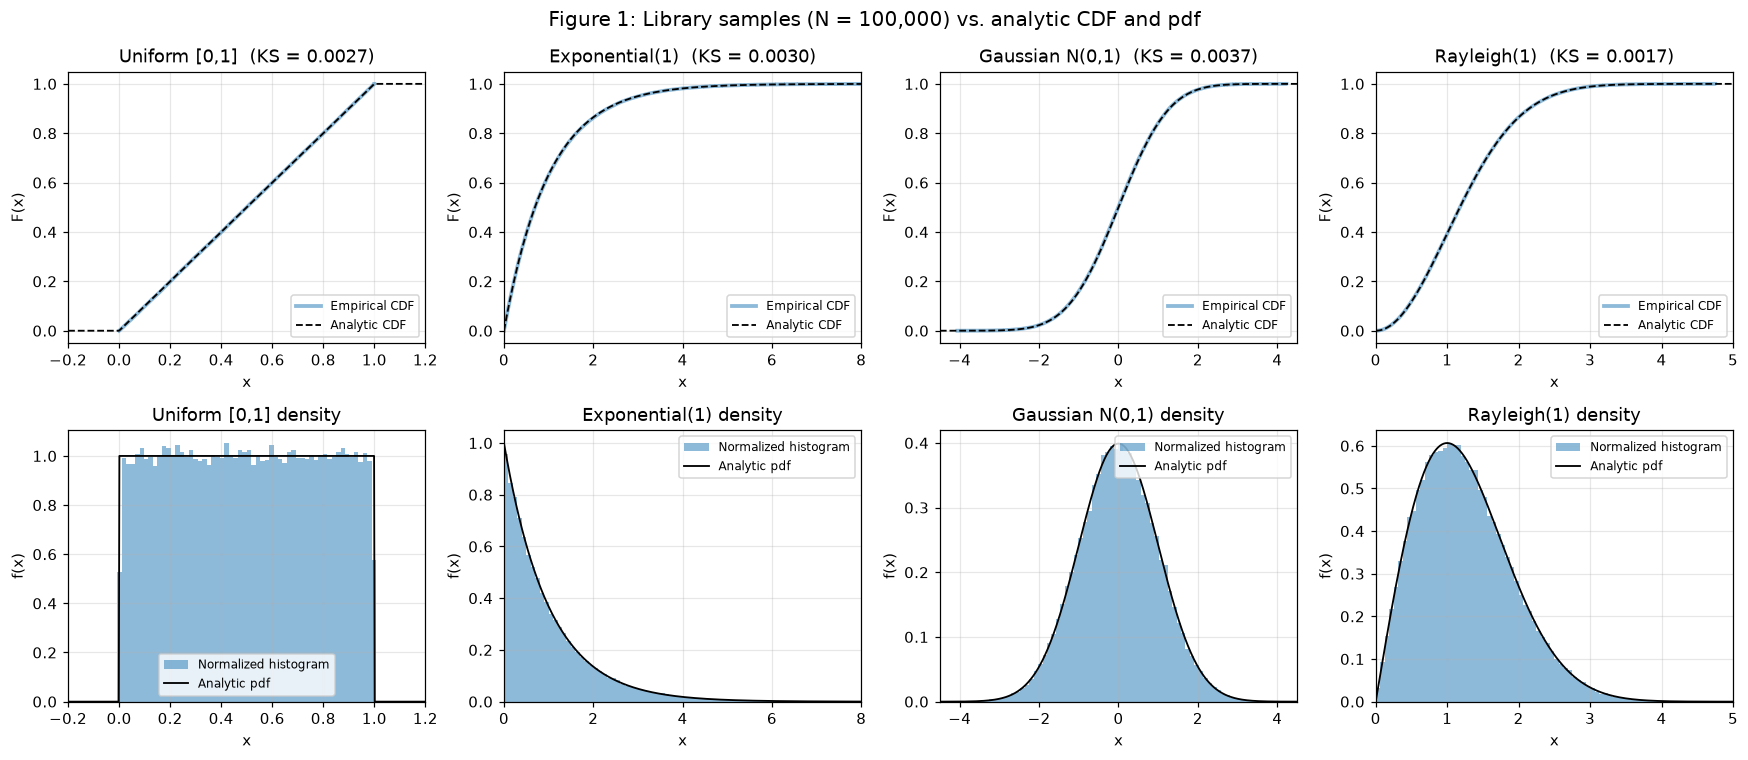

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, (name, (x, cdf, pdf, rg)) in enumerate(dists.items()):
    xs = np.sort(x)
    grid = np.linspace(*rg, 600)
    ax = axes[0, j]
    ax.step(xs, np.arange(1, N1 + 1) / N1, where="post", lw=2.5, alpha=0.5, label="Empirical CDF")
    ax.plot(grid, cdf(grid), "k--", lw=1.2, label="Analytic CDF")
    ax.set_xlim(rg); ax.set_title(f"{name}  (KS = {ks1[name]:.4f})")
    ax.set_xlabel("x"); ax.set_ylabel("F(x)"); ax.legend(fontsize=8, loc="lower right")
    ax = axes[1, j]
    ax.hist(x, bins=80, range=rg, density=True, alpha=0.5, label="Normalized histogram")
    ax.plot(grid, pdf(grid), "k", lw=1.2, label="Analytic pdf")
    ax.set_xlim(rg); ax.set_title(f"{name} density")
    ax.set_xlabel("x"); ax.set_ylabel("f(x)"); ax.legend(fontsize=8, loc="lower center" if j == 0 else "upper right")
fig.suptitle(f"Figure 1: Library samples (N = {N1:,}) vs. analytic CDF and pdf", fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation.** All four KS statistics in the table above fall below the critical value of 0.0043, so none of the four library generators can be distinguished from its analytic CDF at $N = 10^5$; the agreement claim rests on that number, not on the picture. The histograms are normalized with `density=True` (bar height = count / ($N \times$ bin width)) so they are directly comparable to the pdfs. The shapes show the contrast that matters for the rest of the project: the uniform and Gaussian are symmetric about their centers, while the exponential and Rayleigh live on $x \ge 0$ and have long right tails.

In [4]:
lam, sig = 1.0, 1.0
closed = {
    "Exponential(1)": {"mean": 1 / lam, "median": np.log(2) / lam, "variance": 1 / lam**2},
    "Rayleigh(1)":    {"mean": sig * np.sqrt(np.pi / 2), "median": sig * np.sqrt(2 * np.log(2)),
                       "variance": (4 - np.pi) / 2 * sig**2},
}
print(f"{'distribution':<15} {'quantity':<9} {'closed form':>12} {'sample':>9} {'diff':>9}")
for name, cf in closed.items():
    x = dists[name][0]
    sample = {"mean": x.mean(), "median": np.median(x), "variance": x.var(ddof=1)}
    for q in ["mean", "median", "variance"]:
        print(f"{name:<15} {q:<9} {cf[q]:>12.4f} {sample[q]:>9.4f} {sample[q] - cf[q]:>+9.4f}")
x_exp, x_g = dists["Exponential(1)"][0], dists["Gaussian N(0,1)"][0]
print(f"\nExponential mean/median (sample) = {x_exp.mean() / np.median(x_exp):.3f}   (1/ln 2 = {1/np.log(2):.4f})")
print(f"Gaussian mean, median (sample)   = {x_g.mean():+.4f}, {np.median(x_g):+.4f}")

distribution    quantity   closed form    sample      diff
Exponential(1)  mean            1.0000    1.0044   +0.0044
Exponential(1)  median          0.6931    0.6950   +0.0019
Exponential(1)  variance        1.0000    1.0080   +0.0080
Rayleigh(1)     mean            1.2533    1.2538   +0.0005
Rayleigh(1)     median          1.1774    1.1790   +0.0016
Rayleigh(1)     variance        0.4292    0.4307   +0.0015

Exponential mean/median (sample) = 1.445   (1/ln 2 = 1.4427)
Gaussian mean, median (sample)   = -0.0041, -0.0058


### 1.6 Closed forms used

| | Mean | Median | Variance |
|---|---|---|---|
| Exponential($\lambda$) | $1/\lambda = 1$ | $\ln 2/\lambda = 0.6931$ | $1/\lambda^2 = 1$ |
| Rayleigh($\sigma$) | $\sigma\sqrt{\pi/2} = 1.2533$ | $\sigma\sqrt{2\ln 2} = 1.1774$ | $\tfrac{4-\pi}{2}\sigma^2 = 0.4292$ |

The medians come from solving $F(m) = \tfrac12$: $1 - e^{-\lambda m} = \tfrac12 \Rightarrow m = \ln 2/\lambda$, and $1 - e^{-m^2/2\sigma^2} = \tfrac12 \Rightarrow m = \sigma\sqrt{2\ln 2}$. The sample values above match all six closed forms to within sampling error, reproducing the check-yourself numbers.

### 1.7 Why the exponential's mean and median differ

The median only counts probability (half the mass on each side), while the mean weights each value by its distance, so the exponential's long right tail of rare large values pulls the mean out to $1$ while the median stays at $\ln 2$, a ratio of $1/\ln 2 \approx 1.44$. The Gaussian density is symmetric about its center, so every value to the right is matched by an equally likely value the same distance to the left; the balance point and the half-mass point are both the center.

## Step 2: Build your own generator by inversion

### 2.1 The inversion theorem

**Claim.** If $U \sim \mathcal U[0,1]$ and $F$ is a continuous, strictly increasing CDF, then $X = F^{-1}(U)$ has CDF $F$.

**Proof.** Because $F$ is strictly increasing, applying it to both sides of an inequality preserves it, so the events $\{F^{-1}(U) \le x\}$ and $\{U \le F(x)\}$ are the same event. Hence
$$P[X \le x] = P[F^{-1}(U) \le x] = P[U \le F(x)] = F(x),$$
where the last step uses $P[U \le u] = u$ for $u \in [0,1]$. $\blacksquare$

Mechanically: $F^{-1}$ takes the uniform probability axis and stretches it wherever $F$ is flat (where the pdf is small) and compresses it wherever $F$ is steep (where the pdf is large), so equal slices of $u$ land as equal slices of probability in $x$.

### 2.2 Deriving the inverses

**Exponential.** Set $u = F(x)$ and solve for $x$:
$$u = 1 - e^{-\lambda x} \;\Rightarrow\; e^{-\lambda x} = 1 - u \;\Rightarrow\; -\lambda x = \ln(1-u) \;\Rightarrow\; x = F^{-1}(u) = -\frac{\ln(1-u)}{\lambda}.$$

**Rayleigh.**
$$u = 1 - e^{-x^2/2\sigma^2} \;\Rightarrow\; e^{-x^2/2\sigma^2} = 1-u \;\Rightarrow\; -\frac{x^2}{2\sigma^2} = \ln(1-u) \;\Rightarrow\; x^2 = -2\sigma^2\ln(1-u) \;\Rightarrow\; x = F^{-1}(u) = \sigma\sqrt{-2\ln(1-u)},$$
taking the positive root because the support is $x \ge 0$.

In [5]:
N2 = 100_000
x_inv = {
    "Exponential(1)": sample_by_inversion(inv_cdf_exponential, N2, rng2, lam=1.0),
    "Rayleigh(1)":    sample_by_inversion(inv_cdf_rayleigh,    N2, rng2, sigma=1.0),
}
x_lib = {"Exponential(1)": rng2.exponential(1.0, N2), "Rayleigh(1)": rng2.rayleigh(1.0, N2)}  # reference only
cdfs2 = {"Exponential(1)": L.cdf_exponential, "Rayleigh(1)": L.cdf_rayleigh}

crit2 = ks_critical(N2)
crit2b = ks_critical_two_sample(N2, N2)
ks2 = {}
print(f"Inversion sampler, N = {N2:,}, only rng.random() used")
print(f"{'':<15} {'KS vs analytic':>15} {'(crit ' + f'{crit2:.4f})':>14} {'2-sample KS vs library':>23} {'(crit ' + f'{crit2b:.4f})':>14}")
for name in x_inv:
    ks2[name] = ks_statistic(x_inv[name], cdfs2[name])
    k2 = ks_two_sample(x_inv[name], x_lib[name])
    print(f"{name:<15} {ks2[name]:>15.4f} {'pass' if ks2[name] < crit2 else 'FAIL':>14} {k2:>23.4f} {'pass' if k2 < crit2b else 'FAIL':>14}")
print("\nSample means: inversion vs library")
for name in x_inv:
    print(f"  {name:<15} {x_inv[name].mean():.4f} vs {x_lib[name].mean():.4f}")

Inversion sampler, N = 100,000, only rng.random() used
                 KS vs analytic  (crit 0.0043)  2-sample KS vs library  (crit 0.0061)
Exponential(1)           0.0036           pass                  0.0033           pass
Rayleigh(1)              0.0018           pass                  0.0045           pass

Sample means: inversion vs library
  Exponential(1)  1.0011 vs 1.0002
  Rayleigh(1)     1.2531 vs 1.2579


The comparison with the library generator uses the **two-sample** KS statistic, whose 95 percent critical value $1.36\sqrt{(n+m)/nm}$ is $\sqrt2$ larger than the one-sample value because both empirical CDFs now carry sampling noise.

### Figure 2: Inversion-generated samples vs. analytic CDFs

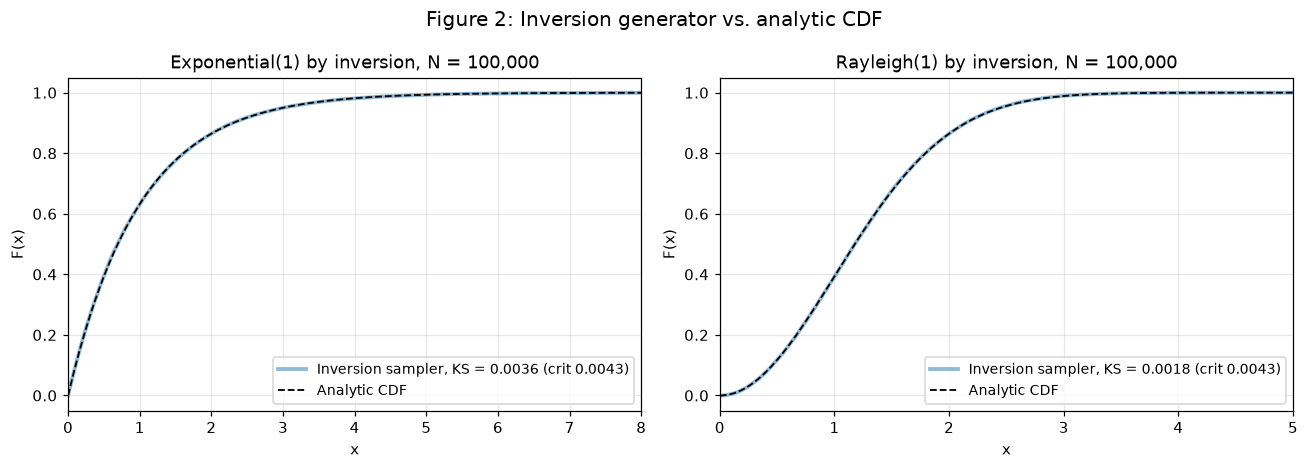

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, (name, x), rg in zip(axes, x_inv.items(), [(0, 8), (0, 5)]):
    xs = np.sort(x); grid = np.linspace(*rg, 500)
    ax.step(xs, np.arange(1, N2 + 1) / N2, where="post", lw=2.5, alpha=0.5,
            label=f"Inversion sampler, KS = {ks2[name]:.4f} (crit {crit2:.4f})")
    ax.plot(grid, cdfs2[name](grid), "k--", lw=1.2, label="Analytic CDF")
    ax.set_xlim(rg); ax.set_xlabel("x"); ax.set_ylabel("F(x)")
    ax.set_title(f"{name} by inversion, N = {N2:,}"); ax.legend(loc="lower right", fontsize=9)
fig.suptitle("Figure 2: Inversion generator vs. analytic CDF", fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation.** Both KS statistics are below the 0.0043 critical value, so the generators built from nothing but `rng.random()` and a closed-form inverse are statistically indistinguishable from the exact distributions, and the two-sample KS shows they are also indistinguishable from NumPy's own exponential and Rayleigh generators. The empirical staircase lies on top of the analytic CDF over the whole range, including the right tail, which is where a wrong constant inside the logarithm or square root would show up first.

### 2.5 The $u = 0$ edge case

In [7]:
u_edge = np.array([0.0, 1e-300, 0.5, 1 - 2.0**-53])   # 1 - 2^-53 is the largest value rng.random() can return
with np.errstate(divide="ignore"):
    print("u                    :", u_edge)
    print("-ln(1-u)  (used)     :", inv_cdf_exponential(u_edge))
    print("-ln(u)    (not used) :", -np.log(u_edge))
    print("Rayleigh sqrt(-2ln(1-u)):", inv_cdf_rayleigh(u_edge))

u                    : [0.e+000 1.e-300 5.e-001 1.e+000]
-ln(1-u)  (used)     : [0.00000000e+000 1.00000000e-300 6.93147181e-001 3.67368006e+001]
-ln(u)    (not used) : [           inf 6.90775528e+02 6.93147181e-01 1.11022302e-16]
Rayleigh sqrt(-2ln(1-u)): [0.00000000e+000 1.41421356e-150 1.17741002e+000 8.57167435e+000]


`rng.random()` draws from $[0, 1)$: exactly 0 is possible (with probability $2^{-53}$ per draw), exactly 1 is not. My inverses use the $1-u$ form, so $u = 0$ maps to $-\ln 1 = 0$, a legitimate sample at the left edge of the support, and the largest possible $u = 1 - 2^{-53}$ maps to $-\ln(2^{-53}) = 36.7$, which is finite. The code can therefore never produce an infinity or a NaN, so no special-case check is needed. The $-\ln(u)$ form would return $+\infty$ at $u = 0$. I also compute $\ln(1-u)$ with `log1p(-u)`, which stays accurate when $u$ is tiny.

### 2.6 Why $-\ln(1-U)$ and $-\ln U$ both work

If $U$ is uniform on $[0,1]$ then so is $1-U$ (reflecting the interval maps each subinterval to one of the same length), so substituting one for the other changes which sample you get from a given draw but not the distribution. I used $-\ln(1-U)/\lambda$, because with `rng.random()`'s half-open interval it is the form that can never return infinity.

## Step 3: A function of a random variable, $Y = X^2$ with $X \sim \mathcal N(0,1)$

### 3.1 CDF of $Y$

$Y \ge 0$ always, so $F_Y(y) = 0$ for $y < 0$. For $y > 0$, squaring is not one-to-one: both $x$ and $-x$ map to the same $y$. The event $\{Y \le y\}$ is exactly $\{-\sqrt y \le X \le \sqrt y\}$, so
$$F_Y(y) = P[-\sqrt y \le X \le \sqrt y] = \Phi(\sqrt y) - \Phi(-\sqrt y) = 2\Phi(\sqrt y) - 1 = 1 - 2Q(\sqrt y),$$
using the symmetry $\Phi(-a) = 1 - \Phi(a)$.

### 3.2 Density of $Y$

Differentiate with the chain rule, $\frac{d}{dy}\sqrt y = \frac{1}{2\sqrt y}$, and $\Phi' = \varphi$:
$$f_Y(y) = \frac{d}{dy}\left[\Phi(\sqrt y) - \Phi(-\sqrt y)\right] = \varphi(\sqrt y)\cdot\frac{1}{2\sqrt y} - \varphi(-\sqrt y)\cdot\left(-\frac{1}{2\sqrt y}\right) = \frac{\varphi(\sqrt y)}{\sqrt y} = \frac{1}{\sqrt{2\pi y}}\,e^{-y/2}, \quad y > 0.$$
This is the chi-square density with one degree of freedom. The two terms add because two branches, $x = +\sqrt y$ and $x = -\sqrt y$, each deliver probability to the same $y$.

### 3.3 Why the density is unbounded at $y \to 0^+$, and why it still integrates to 1

Near the origin the map $y = x^2$ is flat: its slope $dy/dx = 2x$ is zero at $x = 0$. Take the slab $|x| < \delta$. It holds probability $\approx 2\delta\,\varphi(0)$, proportional to $\delta$, but it is compressed into the interval $0 \le y < \delta^2$, whose width is proportional to $\delta^2$. Density is probability per unit width, so near zero
$$f_Y \approx \frac{2\delta\varphi(0)}{\delta^2} \propto \frac{1}{\delta} = \frac{1}{\sqrt y} \;\to\; \infty.$$
The total probability near the origin is still small: $\int_0^\epsilon y^{-1/2}\,dy = 2\sqrt\epsilon \to 0$. The $y^{-1/2}$ singularity is integrable because it diverges more slowly than $1/y$, so the area stays finite while the height does not.

In [8]:
f_Y = lambda y: np.exp(-y / 2) / np.sqrt(2 * np.pi * y)
F_Y = lambda y: np.where(y <= 0, 0.0, 1 - 2 * q_function(np.sqrt(np.maximum(y, 0))))

I_near, e1 = quad(f_Y, 0, 1)          # quad handles the integrable 1/sqrt(y) endpoint singularity
I_far,  e2 = quad(f_Y, 1, np.inf)
print(f"Integral of f_Y over [0,1]   = {I_near:.10f}")
print(f"Integral of f_Y over [1,inf) = {I_far:.10f}")
print(f"Total                        = {I_near + I_far:.10f}  (quad error estimate {e1 + e2:.1e})")
print(f"f_Y at y = 1e-2, 1e-4, 1e-6  = {f_Y(1e-2):.1f}, {f_Y(1e-4):.1f}, {f_Y(1e-6):.1f}   (unbounded)")

Integral of f_Y over [0,1]   = 0.6826894921
Integral of f_Y over [1,inf) = 0.3173105079
Total                        = 1.0000000000  (quad error estimate 2.7e-09)
f_Y at y = 1e-2, 1e-4, 1e-6  = 4.0, 39.9, 398.9   (unbounded)


The density integrates to 1 to ten decimal places even though its value at $y = 10^{-6}$ is about 400 and grows without limit as $y \to 0$.

In [9]:
N3 = 1_000_000
Y = rng3.standard_normal(N3) ** 2

ks3 = ks_statistic(Y, F_Y)
print(f"KS of Y = X^2 vs derived CDF: {ks3:.5f}  (95% critical value at N = {N3:,}: {ks_critical(N3):.5f})")

# Log-spaced bins, 1e-6 .. 30: each bin is a constant ratio wide, so bins near 0 are
# narrow enough to resolve the 1/sqrt(y) spike. density=True divides each count
# by N times that bin's own width, so unequal widths are handled correctly.
bins = np.logspace(-6, np.log10(30), 90)
counts, edges = np.histogram(Y, bins=bins)
dens = counts / (N3 * np.diff(edges))
centers = np.sqrt(edges[:-1] * edges[1:])          # geometric centers on a log axis

small = centers < 1e-2
slope, icpt = np.polyfit(np.log10(centers[small]), np.log10(dens[small]), 1)
print(f"Log-log slope of the histogram for y < 0.01: {slope:.3f}   (predicted -0.5)")

KS of Y = X^2 vs derived CDF: 0.00055  (95% critical value at N = 1,000,000: 0.00136)
Log-log slope of the histogram for y < 0.01: -0.497   (predicted -0.5)


### Figure 3: Histogram of $Y = X^2$ against the derived density

**Binning choice:** log-spaced bins from $10^{-6}$ to 30 (90 bins, each about 21 percent wider than the last), used in both panels. Near zero the bins are as narrow as $10^{-6}$, so the spike is resolved instead of being averaged into one tall first bar.

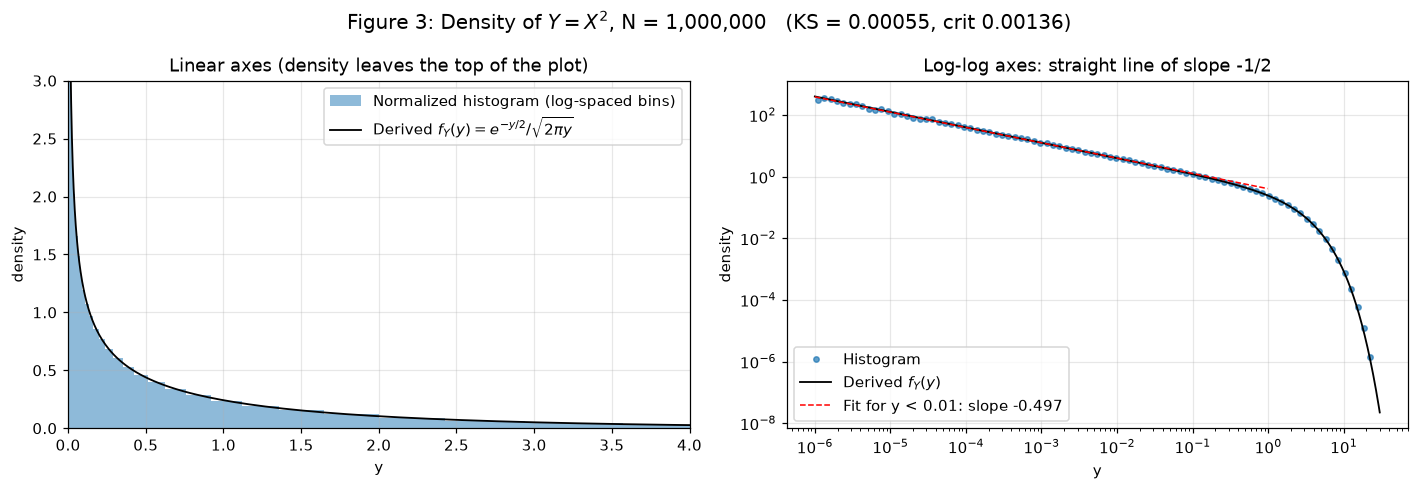

In [10]:
yg = np.logspace(-6, np.log10(30), 600)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.stairs(dens, edges, fill=True, alpha=0.5, label="Normalized histogram (log-spaced bins)")
ax.plot(yg, f_Y(yg), "k", lw=1.2, label=r"Derived $f_Y(y)=e^{-y/2}/\sqrt{2\pi y}$")
ax.set_xlim(0, 4); ax.set_ylim(0, 3)
ax.set_xlabel("y"); ax.set_ylabel("density"); ax.set_title("Linear axes (density leaves the top of the plot)")
ax.legend()
ax = axes[1]
ax.loglog(centers, dens, "o", ms=3.5, alpha=0.7, label="Histogram")
ax.loglog(yg, f_Y(yg), "k", lw=1.2, label=r"Derived $f_Y(y)$")
ax.loglog(yg[yg < 1], 10**icpt * yg[yg < 1]**slope, "r--", lw=1,
          label=f"Fit for y < 0.01: slope {slope:.3f}")
ax.set_xlabel("y"); ax.set_ylabel("density"); ax.set_title("Log-log axes: straight line of slope -1/2")
ax.legend()
fig.suptitle(rf"Figure 3: Density of $Y=X^2$, N = {N3:,}   (KS = {ks3:.5f}, crit {ks_critical(N3):.5f})", fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation.** On linear axes the histogram follows the derived density and shoots off the top of the plot as $y \to 0$; the KS statistic in the title is below the critical value, so the derived CDF is confirmed numerically and not just visually. On log-log axes the divergence becomes a straight line with fitted slope close to $-\tfrac12$. The slope comes straight from the density: for small $y$, $e^{-y/2} \approx 1$, so $f_Y(y) \approx (2\pi)^{-1/2}\,y^{-1/2}$, and $\log f_Y = -\tfrac12\log y + \text{const}$. That exponent $-\tfrac12$ is the $1/\sqrt y$ from the flat-map argument in 3.3, which is ultimately the $\frac{d}{dy}\sqrt y = \frac{1}{2\sqrt y}$ factor of the chain rule. The line bends down for $y \gtrsim 1$, where the exponential factor takes over.

### 3.5 Probabilities and the median

- $P[Y \le 1] = 1 - 2Q(1) = 0.6827$ and $P[Y \le 0.1] = 1 - 2Q(\sqrt{0.1}) = 0.2482$.
- Median: $1 - 2Q(\sqrt m) = \tfrac12 \Rightarrow Q(\sqrt m) = \tfrac14 \Rightarrow m = \left[Q^{-1}(0.25)\right]^2 = 0.6745^2 = 0.4549$.

### 3.6 Mean and variance

$E[Y] = E[X^2] = \mathrm{Var}(X) = 1$. For the variance we need $E[Y^2] = E[X^4]$. Integrate by parts using $x\varphi(x) = -\varphi'(x)$:
$$E[X^4] = \int x^3 \cdot x\varphi(x)\,dx = \left[-x^3\varphi(x)\right]_{-\infty}^{\infty} + \int 3x^2\varphi(x)\,dx = 0 + 3E[X^2] = 3,$$
so $\mathrm{Var}(Y) = E[X^4] - (E[X^2])^2 = 3 - 1 = 2$. The same trick gives $E[X^8] = 105$, which sets the standard error of the sample variance below: $\mathrm{Var}(Y^2) = E[X^8] - (E[X^4])^2 = 96$ for the raw second moment, and the central fourth moment of $Y$ is $60$, so $\mathrm{SE}(s^2) \approx \sqrt{(60 - 2^2)/N}$.

In [11]:
rows = [
    ("P[Y <= 1]",   1 - 2 * q_function(1.0),          np.mean(Y <= 1),   0.6827),
    ("P[Y <= 0.1]", 1 - 2 * q_function(np.sqrt(0.1)), np.mean(Y <= 0.1), 0.2482),
]
print(f"N = {N3:,} samples of Y")
print(f"{'quantity':<12} {'analytic':>9} {'empirical':>10} {'std. err':>9} {'z':>6} {'handout':>8}")
for name, a, e, h in rows:
    se = np.sqrt(a * (1 - a) / N3)
    print(f"{name:<12} {a:>9.4f} {e:>10.4f} {se:>9.5f} {(e - a) / se:>6.2f} {h:>8.4f}")

med_a = q_inverse(0.25) ** 2
med_se = np.sqrt(0.25 / N3) / f_Y(med_a)           # asymptotic SE of a sample median: 1/(2 f(m) sqrt N)
med_e = np.median(Y)
print(f"{'median':<12} {med_a:>9.4f} {med_e:>10.4f} {med_se:>9.5f} {(med_e - med_a) / med_se:>6.2f} {0.4549:>8.4f}")
mean_se, var_se = np.sqrt(2 / N3), np.sqrt((60 - 4) / N3)
print(f"{'mean':<12} {1.0:>9.4f} {Y.mean():>10.4f} {mean_se:>9.5f} {(Y.mean() - 1) / mean_se:>6.2f} {1.0:>8.4f}")
print(f"{'variance':<12} {2.0:>9.4f} {Y.var(ddof=1):>10.4f} {var_se:>9.5f} {(Y.var(ddof=1) - 2) / var_se:>6.2f} {2.0:>8.4f}")

N = 1,000,000 samples of Y
quantity      analytic  empirical  std. err      z  handout
P[Y <= 1]       0.6827     0.6829   0.00047   0.48   0.6827
P[Y <= 0.1]     0.2482     0.2481   0.00043  -0.25   0.2482
median          0.4549     0.4549   0.00106  -0.06   0.4549
mean            1.0000     1.0001   0.00141   0.08   1.0000
variance        2.0000     2.0047   0.00748   0.63   2.0000


All five quantities reproduce the check-yourself values, and every empirical value is within a few standard errors of the analytic one (the `z` column). The median, 0.455, is less than half the mean of 1: the infinite density at the origin piles half the probability into $[0, 0.455]$, while the mean is pulled up by the long right tail inherited from $X^2$.

## Step 4: Expectation and moments

### 4.1 Rayleigh raw moments

With $f(x) = \frac{x}{\sigma^2}e^{-x^2/2\sigma^2}$, substitute $t = x^2/2\sigma^2$, so $x = \sigma\sqrt{2t}$ and $dt = x\,dx/\sigma^2$:
$$E[X^n] = \int_0^\infty x^n \frac{x}{\sigma^2}e^{-x^2/2\sigma^2}dx = \int_0^\infty (2\sigma^2 t)^{n/2} e^{-t}\,dt = (2\sigma^2)^{n/2}\,\Gamma\!\left(1 + \tfrac n2\right).$$
For $\sigma = 1$:

| $n$ | $2^{n/2}\Gamma(1+n/2)$ | value |
|---|---|---|
| 1 | $\sqrt2\,\Gamma(3/2) = \sqrt2\cdot\frac{\sqrt\pi}{2} = \sqrt{\pi/2}$ | 1.2533 |
| 2 | $2\,\Gamma(2) = 2$ | 2 |
| 3 | $2\sqrt2\,\Gamma(5/2) = 2\sqrt2\cdot\frac{3\sqrt\pi}{4} = 3\sqrt{\pi/2}$ | 3.7599 |
| 4 | $4\,\Gamma(3) = 8$ | 8 |

The standard error of the sample mean of $X^n$ is $\sqrt{\mathrm{Var}(X^n)/N} = \sqrt{(E[X^{2n}] - E[X^n]^2)/N}$, using the same formula for the $2n$-th moment.

In [12]:
N4 = 1_000_000
R = rng4.rayleigh(1.0, N4)
raw = lambda n, s=1.0: (2 * s**2) ** (n / 2) * gamma_fn(1 + n / 2)

print(f"Rayleigh(1) raw moments, N = {N4:,}")
print(f"{'n':>2} {'theory':>8} {'sample':>8} {'std. err':>9} {'diff / SE':>10}")
for n in range(1, 5):
    th = raw(n); sm = np.mean(R**n)
    se = np.sqrt((raw(2 * n) - th**2) / N4)
    print(f"{n:>2} {th:>8.4f} {sm:>8.4f} {se:>9.5f} {(sm - th) / se:>10.2f}")

Rayleigh(1) raw moments, N = 1,000,000
 n   theory   sample  std. err  diff / SE
 1   1.2533   1.2539   0.00066       0.86
 2   2.0000   2.0008   0.00200       0.41
 3   3.7599   3.7603   0.00582       0.06
 4   8.0000   7.9976   0.01789      -0.13


All four sample moments sit within about two standard errors of theory. The standard error grows with $n$ because higher powers amplify the tail: $X^4$ is a much noisier quantity than $X$.

### 4.2 Pareto with shape 1.5: the mean exists, the second moment does not

$f(x) = 1.5\,x^{-2.5}$ for $x \ge 1$.

$$E[X] = \int_1^\infty x\cdot 1.5x^{-2.5}\,dx = 1.5\int_1^\infty x^{-1.5}\,dx = 1.5\left[\frac{x^{-0.5}}{-0.5}\right]_1^\infty = 1.5\,(0 + 2) = 3.$$

$$E[X^2] = \int_1^\infty x^2\cdot 1.5x^{-2.5}\,dx = 1.5\int_1^\infty x^{-0.5}\,dx = 1.5\left[2x^{0.5}\right]_1^\infty = \infty.$$

The integrand of $E[X^k]$ is $\propto x^{k - 2.5}$, which is integrable at infinity only when $k - 2.5 < -1$, i.e. $k < 1.5$. So the mean exists, but the second moment, and therefore the variance, does not.

Samples by inversion (Step 2): $F(x) = 1 - x^{-1.5} \Rightarrow X = (1-U)^{-1/1.5}$.

In [13]:
P = sample_by_inversion(lambda u: (1 - u) ** (-1 / 1.5), N4, rng4)    # Pareto(1.5, 1)

mR, vR = running_mean_var(R)
mP, vP = running_mean_var(P)
print(f"{'N':>9} {'Pareto mean':>12} {'Pareto var':>11} {'largest sample so far':>22}   {'Rayleigh mean':>13} {'Rayleigh var':>12}")
for n in [10**3, 10**4, 10**5, 10**6]:
    print(f"{n:>9,} {mP[n-1]:>12.4f} {vP[n-1]:>11.2f} {P[:n].max():>22.1f}   {mR[n-1]:>13.4f} {vR[n-1]:>12.4f}")
print(f"\nTheory: Pareto mean 3, Pareto variance does not exist; Rayleigh mean {raw(1):.4f}, variance {(4 - np.pi) / 2:.4f}")

        N  Pareto mean  Pareto var  largest sample so far   Rayleigh mean Rayleigh var
    1,000       2.5980       15.54                   59.1          1.2546       0.4420
   10,000       2.8637       52.23                  258.6          1.2615       0.4358
  100,000       2.9548      146.99                 2140.1          1.2556       0.4307
1,000,000       3.0096     1194.97                22298.6          1.2539       0.4286

Theory: Pareto mean 3, Pareto variance does not exist; Rayleigh mean 1.2533, variance 0.4292


### Figure 4: Running mean and running sample variance

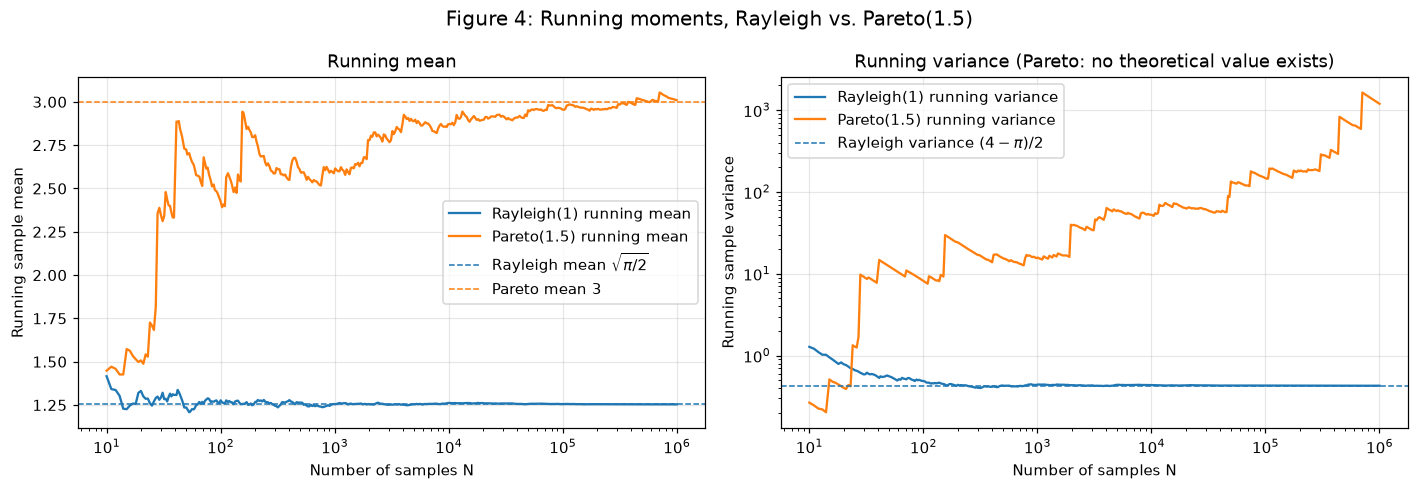

In [14]:
idx = np.unique(np.logspace(1, 6, 400).astype(int)) - 1
n_ax = idx + 1
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.semilogx(n_ax, mR[idx], label="Rayleigh(1) running mean")
ax.semilogx(n_ax, mP[idx], label="Pareto(1.5) running mean")
ax.axhline(raw(1), color="C0", ls="--", lw=1, label=r"Rayleigh mean $\sqrt{\pi/2}$")
ax.axhline(3, color="C1", ls="--", lw=1, label="Pareto mean 3")
ax.set_xlabel("Number of samples N"); ax.set_ylabel("Running sample mean")
ax.set_title("Running mean"); ax.legend()
ax = axes[1]
ax.loglog(n_ax, vR[idx], label="Rayleigh(1) running variance")
ax.loglog(n_ax, vP[idx], label="Pareto(1.5) running variance")
ax.axhline((4 - np.pi) / 2, color="C0", ls="--", lw=1, label=r"Rayleigh variance $(4-\pi)/2$")
ax.set_xlabel("Number of samples N"); ax.set_ylabel("Running sample variance")
ax.set_title("Running variance (Pareto: no theoretical value exists)"); ax.legend()
fig.suptitle("Figure 4: Running moments, Rayleigh vs. Pareto(1.5)", fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation.** Both running means converge: the Rayleigh mean locks onto 1.2533 within a few thousand samples, and the Pareto mean wanders more but drifts toward 3, because $E[X]$ is finite and the law of large numbers only needs a finite mean. The variance panel is where the two separate. The Rayleigh running variance flattens onto 0.4292. The Pareto running variance never flattens: it climbs in jumps, each jump lining up with the arrival of a new largest sample, then decays as $1/N$ until the next one (the printed "largest sample so far" column grows along with the variance). The handout expects values in the tens to hundreds; any value is equally "right" here, because there is no true value for it to converge to, and a different seed would give a different trajectory.

### 4.4 Why the sample variance is still a number

Any finite set of finite numbers has a finite sum of squares, so the formula $s^2 = \frac{1}{N-1}\sum(x_i - \bar x)^2$ always returns something, and nothing in the code can know that the population variance it is meant to estimate is infinite. What it actually measures is how large the biggest samples drawn so far happen to be: it is dominated by $\max_i x_i^2/N$, and because the largest of $N$ Pareto(1.5) samples grows like $N^{1/1.5}$, it drifts upward roughly like $N^{1/3}$ and is set by a handful of points rather than by the distribution.

### 4.5 The practical rule for error bars

An error bar of $s/\sqrt N$ is only meaningful if the variance exists, so before reporting one, check that the running sample variance actually settles as $N$ grows (or that the tail decays faster than $x^{-3}$); if it does not, report the median with a quantile- or bootstrap-based interval instead, and say that the data are heavy-tailed.

## Step 5: The central limit theorem, and where it fails

### 5.1 Standardizing a sum of $N$ uniforms

For $U \sim \mathcal{U}[0,1]$:
$$E[U] = \int_0^1 u\,du = \tfrac12, \qquad E[U^2] = \int_0^1 u^2\,du = \tfrac13, \qquad \mathrm{Var}(U) = \tfrac13 - \tfrac14 = \tfrac{1}{12}.$$
For $S_N = \sum_{k=1}^N U_k$ with independent $U_k$, expectation is linear and variances of independent terms add:
$$E[S_N] = \frac{N}{2}, \qquad \mathrm{Var}(S_N) = \frac{N}{12}, \qquad Z_N = \frac{S_N - N/2}{\sqrt{N/12}}.$$
$Z_N$ has mean 0 and variance 1 exactly for every $N$; the CLT says its CDF approaches $\Phi$.

In [15]:
M = 200_000                                  # independent sums per N
N_unif = np.array([1, 2, 3, 5, 10, 30])
crit5 = ks_critical(M)
ks_floor = 0.8687 / np.sqrt(M)               # expected KS of an exactly Gaussian sample of size M

ks_unif, Z_unif = [], {}
for N in N_unif:
    S = rng5.random((M, N)).sum(axis=1)      # M sums of N uniforms, vectorized
    Z = (S - N / 2) / np.sqrt(N / 12)
    Z_unif[N] = Z
    ks_unif.append(ks_statistic(Z, std_normal_cdf))
ks_unif = np.array(ks_unif)

handout5 = [0.058, 0.018, 0.011, 0.007, 0.004, 0.003]
print(f"Uniform summands, M = {M:,} sums per N, 95% KS critical value = {crit5:.4f}")
print(f"{'N':>4} {'mean(Z)':>9} {'var(Z)':>8} {'KS':>8} {'handout':>8}  vs crit")
for N, d, h in zip(N_unif, ks_unif, handout5):
    Z = Z_unif[N]
    print(f"{N:>4} {Z.mean():>9.4f} {Z.var():>8.4f} {d:>8.4f} {h:>8.3f}  {'above' if d > crit5 else 'below'}")

fit = N_unif <= 10                           # N = 30 sits on the sampling floor (see below)
slope5, _ = np.polyfit(np.log10(N_unif[fit]), np.log10(ks_unif[fit]), 1)
print(f"\nSampling floor (expected KS of an exactly Gaussian sample of size M): {ks_floor:.4f}")
print(f"Log-log fit over N = 1..10: KS ~ N^{slope5:.2f}")

Uniform summands, M = 200,000 sums per N, 95% KS critical value = 0.0030
   N   mean(Z)   var(Z)       KS  handout  vs crit
   1   -0.0035   0.9989   0.0583    0.058  above
   2    0.0017   1.0006   0.0170    0.018  above
   3   -0.0006   1.0025   0.0101    0.011  above
   5   -0.0048   0.9972   0.0069    0.007  above
  10   -0.0017   1.0020   0.0046    0.004  above
  30   -0.0014   1.0012   0.0026    0.003  below

Sampling floor (expected KS of an exactly Gaussian sample of size M): 0.0019
Log-log fit over N = 1..10: KS ~ N^-1.08


### 5.4 Pareto summands

Pareto(1.5), sampled by inversion as in Step 4. Its variance is infinite (Step 4.2), so there is no $\sigma^2$ to standardize with; each set of $M$ sums is standardized with its own **sample** mean and standard deviation, which is the only "zero mean, unit variance" available. KS is computed after an affine standardization, so any other centering and scaling would give the same shape. Sums are built in chunks so $N = 1000$ ($2\times10^8$ draws) stays under about 160 MB.

In [16]:
def pareto_sums(N, M, rng, alpha=1.5, chunk=20_000_000):
    out = np.empty(M)
    rows = max(1, chunk // N)
    for k in range(0, M, rows):
        m = min(rows, M - k)
        out[k:k + m] = ((1.0 - rng.random((m, N))) ** (-1.0 / alpha)).sum(axis=1)
    return out

N_par = np.array([1, 10, 100, 1000])
print(f"Pareto(1.5) summands, M = {M:,} sums per N, 95% KS critical value = {crit5:.4f}")
ks_par = []
for N in N_par:
    S = pareto_sums(N, M, rng5)
    Z = (S - S.mean()) / S.std()
    ks_par.append(ks_statistic(Z, std_normal_cdf))
    print(f"N = {N:>4}: sample std of S_N = {S.std():10.1f}   KS = {ks_par[-1]:.4f}")
ks_par = np.array(ks_par)

Pareto(1.5) summands, M = 200,000 sums per N, 95% KS critical value = 0.0030
N =    1: sample std of S_N =       15.5   KS = 0.4498
N =   10: sample std of S_N =      128.3   KS = 0.4435
N =  100: sample std of S_N =      350.1   KS = 0.3764
N = 1000: sample std of S_N =     1359.2   KS = 0.3350


### Figure 5: KS distance from Gaussian vs. number of summands

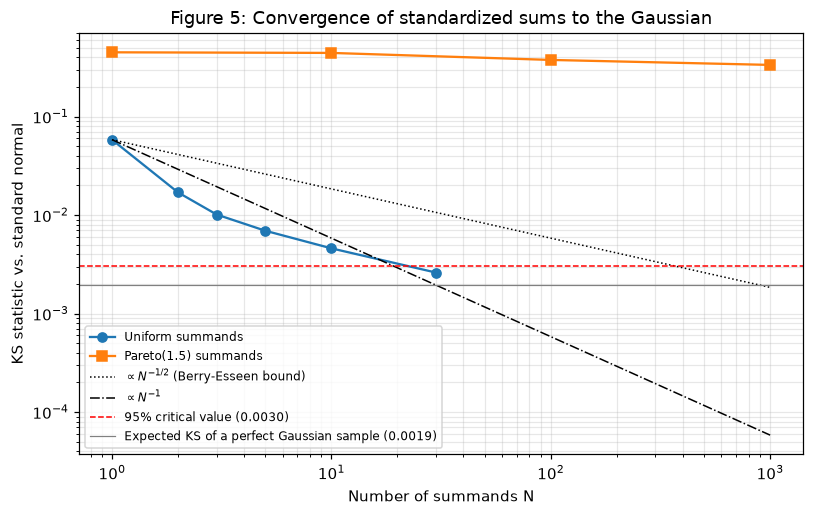

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.loglog(N_unif, ks_unif, "o-", label="Uniform summands")
ax.loglog(N_par, ks_par, "s-", label="Pareto(1.5) summands")
Nref = np.array([1, 1000])
ax.loglog(Nref, ks_unif[0] * Nref ** -0.5, "k:", lw=1, label=r"$\propto N^{-1/2}$ (Berry-Esseen bound)")
ax.loglog(Nref, ks_unif[0] * Nref ** -1.0, "k-.", lw=1, label=r"$\propto N^{-1}$")
ax.axhline(crit5, color="r", ls="--", lw=1, label=f"95% critical value ({crit5:.4f})")
ax.axhline(ks_floor, color="gray", lw=0.8, label=f"Expected KS of a perfect Gaussian sample ({ks_floor:.4f})")
ax.set_xlabel("Number of summands N"); ax.set_ylabel("KS statistic vs. standard normal")
ax.set_title("Figure 5: Convergence of standardized sums to the Gaussian")
ax.grid(True, which="both", alpha=0.3); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** The uniform curve falls as a straight line on log-log axes, but with a fitted slope near $-1$, not the $-\tfrac12$ the handout describes: from $N = 1$ to $N = 10$ the KS distance drops by more than a factor of 10, where $1/\sqrt N$ would give only $\sqrt{10} \approx 3.2$. Berry–Esseen guarantees $1/\sqrt N$ only as an *upper bound* for summands with a finite third moment, and that worst case is driven by skewness. The uniform is symmetric, so its skewness is zero and the $1/\sqrt N$ term of the Edgeworth expansion vanishes; the leading error comes from the excess kurtosis ($-1.2$) and shrinks like $1/N$, about $0.028/N$ in CDF error. By $N = 30$ that true error (≈0.001) is smaller than the KS that a *perfectly* Gaussian sample of $2\times10^5$ points produces on average (gray line), so the $N = 30$ point measures sampling noise, which is why it is left out of the slope fit. The handout's check values (0.058, 0.018, …, 0.003) match the table above within that noise; only its "falls like $1/\sqrt N$" description does not.

The Pareto curve is flat: a thousandfold increase in $N$ leaves the KS distance around 0.3–0.5, about 100 times the critical value.

### Figure 6: Standardized uniform sums at $N = 1, 3, 30$

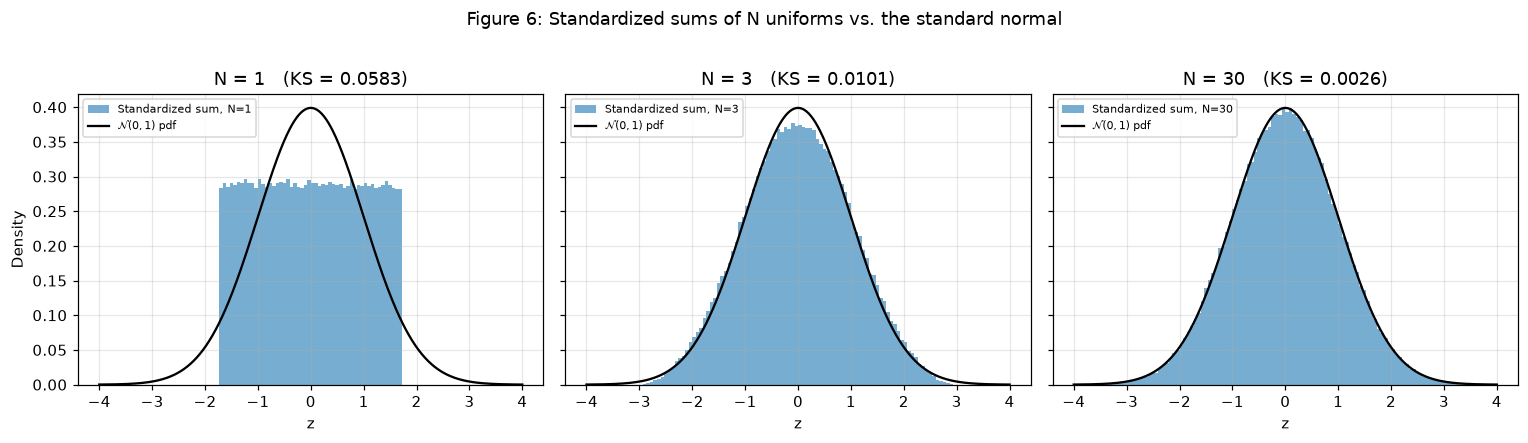

In [18]:
z = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, N in zip(axes, [1, 3, 30]):
    ax.hist(Z_unif[N], bins=120, range=(-4, 4), density=True, alpha=0.6, label=f"Standardized sum, N={N}")
    ax.plot(z, std_normal_pdf(z), "k", lw=1.5, label=r"$\mathcal{N}(0,1)$ pdf")
    ax.set_title(f"N = {N}   (KS = {ks_unif[list(N_unif).index(N)]:.4f})")
    ax.set_xlabel("z"); ax.legend(fontsize=7, loc="upper left")
axes[0].set_ylabel("Density")
fig.suptitle("Figure 6: Standardized sums of N uniforms vs. the standard normal", y=1.02)
plt.tight_layout(); plt.show()

**Interpretation.** At $N = 1$ the standardized variable is uniform on $[-\sqrt3, \sqrt3]$: a flat box with no probability beyond $|z| = 1.73$. At $N = 3$ the density is three parabolic pieces joined smoothly (the uniform convolved with itself three times), already bell-shaped, with the remaining error in the tails, which are still exactly zero beyond $|z| = 3$. At $N = 30$ the histogram and the normal pdf are indistinguishable by eye; only the KS statistic, computed from $2\times10^5$ samples, can measure what difference remains.

### 5.3 Statistically distinguishable vs. practically different

The sum of 30 uniforms is never exactly Gaussian (it is bounded to $|z| \le \sqrt{90} \approx 9.5$, and its CDF differs from $\Phi$ by about 0.001), so a large enough sample will always reject it; that is not a failure of the CLT, which is a statement about the limit $N \to \infty$ and promises only that the error shrinks to zero, not that it is zero at any finite $N$. The critical value $1.36/\sqrt M$ shrinks with the sample size, so whether $N = 30$ "passes" depends as much on $M$ as on the distribution: at $M = 2\times10^5$ the true error sits right at the test's resolution and the outcome is decided by sampling noise, while at $M = 10^7$ it would be rejected every time. A distribution is *statistically distinguishable* from Gaussian whenever enough data exposes any nonzero difference, but it is *practically different* only when the difference changes an answer you care about: a CDF error of 0.001 is irrelevant for a 5 percent quantile, yet decisive for a $10^{-6}$ false alarm probability (Step 6), because the true tail beyond $|z| = 9.5$ is zero while the Gaussian's is not.

### 5.5 Why Pareto convergence stalls

The classical CLT requires the summands to have **finite variance**, and Pareto(1.5) does not (Step 4.2), so the sum is dominated by its few largest terms instead of by the accumulation of many comparable ones. By the generalized CLT (Gnedenko–Kolmogorov), $(S_N - 3N)/N^{1/\alpha} = (S_N - 3N)/N^{2/3}$ converges to an **$\alpha$-stable (Lévy) distribution with $\alpha = 1.5$**, totally skewed to the right ($\beta = 1$), which has a finite mean but infinite variance and a power-law tail $\propto x^{-1.5}$; no rescaling of a distribution with that tail can look Gaussian. The printed sample standard deviations grow faster than $\sqrt N$ and jump erratically, the Step 4 behavior again: the "standard deviation" used to standardize each sum is not estimating any fixed number.

## Step 6: A threshold detector in Gaussian noise

### 6.1 False alarm and detection probabilities

Define $Q(x) = P[Z > x] = \int_x^\infty \frac{1}{\sqrt{2\pi}}e^{-t^2/2}\,dt$ for $Z \sim \mathcal N(0,1)$.

**False alarm** (detection declared, noise only). Under $H_0$, $X \sim \mathcal N(0,\sigma^2)$, so $X/\sigma \sim \mathcal N(0,1)$:
$$P_{FA} = P[X > T \mid H_0] = P\!\left[\frac{X}{\sigma} > \frac{T}{\sigma}\right] = Q\!\left(\frac{T}{\sigma}\right).$$

**Detection** (detection declared, signal present). Under $H_1$, $X \sim \mathcal N(A,\sigma^2)$, so $(X-A)/\sigma \sim \mathcal N(0,1)$:
$$P_D = P[X > T \mid H_1] = P\!\left[\frac{X-A}{\sigma} > \frac{T-A}{\sigma}\right] = Q\!\left(\frac{T-A}{\sigma}\right).$$

Both use the same move: shift and scale $X$ into a standard normal, and the threshold moves with it.

### 6.2 Q from erfc

$\mathrm{erfc}(y) = \frac{2}{\sqrt\pi}\int_y^\infty e^{-s^2}ds$. Substituting $t = \sqrt2\,s$ in the definition of $Q$:
$$Q(x) = \frac{1}{\sqrt{2\pi}}\int_x^\infty e^{-t^2/2}\,dt = \frac{1}{\sqrt{2\pi}}\int_{x/\sqrt2}^\infty e^{-s^2}\sqrt2\,ds = \frac12\,\mathrm{erfc}\!\left(\frac{x}{\sqrt2}\right).$$
`erfc` computes the small tail value directly, with full relative precision. Computing $1 - \Phi(x)$ instead subtracts two numbers that agree to many digits and returns exactly 0 at $x = 8.3$.

In [19]:
xs = np.array([1.0, 3.0, 5.2, 8.3])
print(f"{'x':>5} {'q_function(x)':>17} {'scipy norm.sf':>17} {'rel. error':>11} {'1 - norm.cdf':>13}")
for x, a, b in zip(xs, q_function(xs), norm.sf(xs)):
    print(f"{x:>5.1f} {a:>17.10e} {b:>17.10e} {abs(a - b) / b:>11.1e} {1 - norm.cdf(x):>13.4e}")

    x     q_function(x)     scipy norm.sf  rel. error  1 - norm.cdf
  1.0  1.5865525393e-01  1.5865525393e-01     0.0e+00    1.5866e-01
  3.0  1.3498980316e-03  1.3498980316e-03     1.9e-15    1.3499e-03
  5.2  9.9644263169e-08  9.9644263169e-08     1.2e-15    9.9644e-08
  8.3  5.2055697449e-17  5.2055697449e-17     7.5e-15    0.0000e+00


`q_function` agrees with the library routine to about 15 significant digits at all four arguments, including $x = 5.2$, where $Q \approx 10^{-7}$, so it meets both the six-digit and the $10^{-7}$ requirements. The last column shows the trap: $1-\Phi(x)$ loses digits as $x$ grows and is exactly zero at $x = 8.3$.

### 6.3 Threshold for a specified false alarm probability

$Q$ is strictly decreasing, so $P_{FA} = Q(T/\sigma)$ inverts uniquely:
$$\frac{T}{\sigma} = Q^{-1}(P_{FA}) = \sqrt2\,\mathrm{erfc}^{-1}(2P_{FA}), \qquad P_D = Q\!\left(Q^{-1}(P_{FA}) - \frac{A}{\sigma}\right).$$

In [20]:
A6 = 3.0
pfa_list = np.array([1e-2, 1e-3, 1e-4, 1e-6])
T6 = q_inverse(pfa_list)
PD6 = q_function(T6 - A6)
print(f"Gaussian threshold detector, A/sigma = {A6}")
print(f"{'P_FA':>8} {'T/sigma':>9} {'P_D':>8}")
for p, t, d in zip(pfa_list, T6, PD6):
    print(f"{p:>8.0e} {t:>9.4f} {d:>8.4f}")
print("\nHandout: P_FA 1e-3 -> T = 3.0902, P_D = 0.4641;  P_FA 1e-6 -> T = 4.7534, P_D = 0.0398")

Gaussian threshold detector, A/sigma = 3.0
    P_FA   T/sigma      P_D
   1e-02    2.3263   0.7497
   1e-03    3.0902   0.4641
   1e-04    3.7190   0.2361
   1e-06    4.7534   0.0398

Handout: P_FA 1e-3 -> T = 3.0902, P_D = 0.4641;  P_FA 1e-6 -> T = 4.7534, P_D = 0.0398


### 6.4 Monte Carlo check of two rows

A Monte Carlo estimate from $n$ independent trials is a scaled binomial count, so its standard error is $\sqrt{p(1-p)/n}$, and a 10 percent relative error needs $\sqrt{(1-p)/(np)} \le 0.1$, i.e. $n \approx 100/p$. The $P_{FA} = 10^{-4}$ row therefore needs at least $10^6$ noise-only trials; I use $4\times10^6$ for about 5 percent, generated in chunks of $10^6$.

In [21]:
n6 = 4_000_000
print(f"Monte Carlo, n = {n6:,} trials per hypothesis, sigma = 1, A = {A6}")
print(f"{'quantity':<15} {'analytic':>11} {'MC estimate':>12} {'std. err':>10} {'rel. SE':>8} {'z':>6}")
for p in [1e-2, 1e-4]:
    T = q_inverse(p)
    for name, mean, exact in [("P_FA", 0.0, p), ("P_D", A6, q_function(T - A6))]:
        hits = count_exceedances(lambda m, r, mu=mean: r.standard_normal(m) + mu, T, n6, rng6)
        est, se = mc_probability(hits, n6)
        print(f"{name + f' @ {p:.0e}':<15} {exact:>11.4e} {est:>12.4e} {se:>10.2e} {se / est:>8.1%} {(est - exact) / se:>6.2f}")

Monte Carlo, n = 4,000,000 trials per hypothesis, sigma = 1, A = 3.0
quantity           analytic  MC estimate   std. err  rel. SE      z
P_FA @ 1e-02     1.0000e-02   1.0138e-02   5.01e-05     0.5%   2.75
P_D @ 1e-02      7.4973e-01   7.4990e-01   2.17e-04     0.0%   0.79
P_FA @ 1e-04     1.0000e-04   1.0025e-04   5.01e-06     5.0%   0.05
P_D @ 1e-04      2.3607e-01   2.3610e-01   2.12e-04     0.1%   0.15


Every estimate lies within three standard errors of its analytic value (the `z` column), which is what agreement means for a random estimate; with several estimates checked at once, an occasional one between 2 and 3 SE is expected by chance. At $P_{FA} = 10^{-4}$, $4\times10^6$ trials produce only about 400 false alarms, and that count, not the trial count, sets the precision: $1/\sqrt{400} = 5$ percent.

### Figure 7: ROC curves

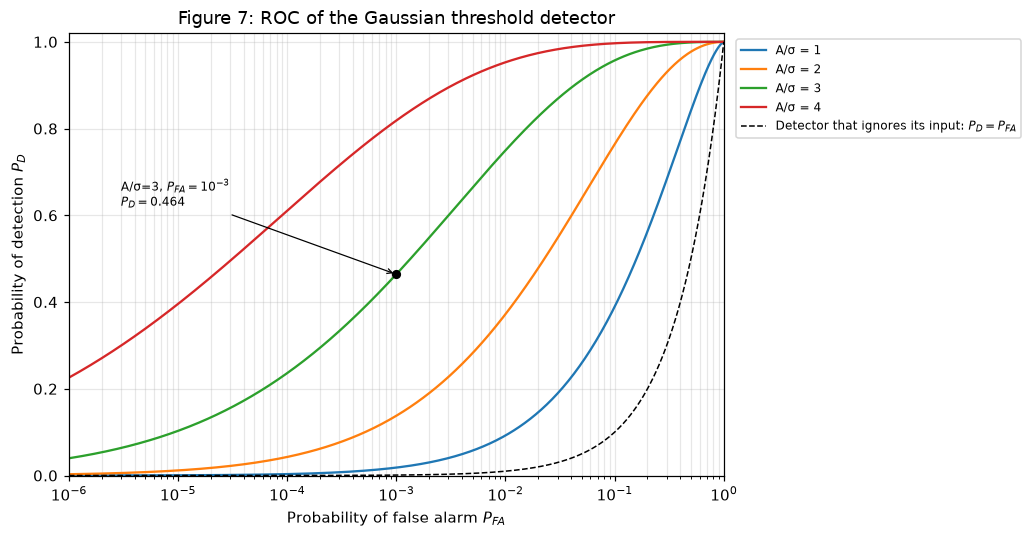

In [22]:
pfa_grid = np.logspace(-6, 0, 600)
fig, ax = plt.subplots(figsize=(9.5, 5))
for snr in [1, 2, 3, 4]:
    ax.semilogx(pfa_grid, q_function(q_inverse(pfa_grid) - snr), label=f"A/σ = {snr}")
ax.semilogx(pfa_grid, pfa_grid, "k--", lw=1, label="Detector that ignores its input: $P_D = P_{FA}$")
ax.plot(1e-3, q_function(q_inverse(1e-3) - 3), "ko", ms=5)
ax.annotate("A/σ=3, $P_{FA}=10^{-3}$\n$P_D=0.464$", (1e-3, 0.464), xytext=(3e-6, 0.62),
            arrowprops=dict(arrowstyle="->", lw=0.8), fontsize=8)
ax.set_xlim(1e-6, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("Probability of false alarm $P_{FA}$"); ax.set_ylabel("Probability of detection $P_D$")
ax.set_title("Figure 7: ROC of the Gaussian threshold detector")
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** Each curve is traced by sweeping $T$ from $+\infty$ (lower left: never declare) to $-\infty$ (upper right: always declare); the designer only chooses where on the curve to sit, while the SNR decides which curve is available. Higher $A/\sigma$ lifts the whole curve: at $P_{FA} = 10^{-3}$, going from $A/\sigma = 2$ to $4$ raises $P_D$ from 0.14 to 0.82. Every curve falls steeply as $P_{FA}$ is pushed toward $10^{-6}$, because $T$ must climb into the noise tail and leaves the fixed signal mean further below it: even $A/\sigma = 3$ catches only 4 percent of targets at $P_{FA} = 10^{-6}$.

### 6.6 A detector that ignores its input

A detector that ignores $X$ and declares "signal" by flipping a coin with probability $p$ has $P_D = P_{FA} = p$, because the coin cannot tell which hypothesis is true, so its ROC is the diagonal $P_D = P_{FA}$. On these log-x axes that diagonal is the dashed curve hugging the bottom of the plot (it reaches only $P_D = 10^{-3}$ at $P_{FA} = 10^{-3}$ and rises to the corner only at $P_{FA} = 1$); every real detector lies above it, and the vertical gap is what the measurement contributes.

## Step 7: The envelope detector, and what a wrong noise estimate costs

With noise only, the receiver sees $R = |N_I + jN_Q|$ with $N_I, N_Q \sim \mathcal N(0,\sigma^2)$ independent; $R$ is Rayleigh with **scale** $\sigma$ (not standard deviation: the Rayleigh's standard deviation is $\sqrt{(4-\pi)/2}\,\sigma = 0.655\sigma$).

### 7.1 False alarm probability

From the Rayleigh CDF of Step 1, the tail is one line:
$$P_{FA} = P[R > T] = 1 - F_R(T) = e^{-T^2/2\sigma^2}.$$

### 7.2 Inverting it

$$\ln P_{FA} = -\frac{T^2}{2\sigma^2} \;\Rightarrow\; T^2 = -2\sigma^2\ln P_{FA} \;\Rightarrow\; \frac{T}{\sigma} = \sqrt{-2\ln P_{FA}}.$$

In [23]:
T7 = np.sqrt(-2 * np.log(pfa_list))
print(f"Envelope (Rayleigh) detector thresholds")
print(f"{'P_FA':>8} {'T/sigma':>9}   (Gaussian detector, Step 6)")
for p, t, tg in zip(pfa_list, T7, T6):
    print(f"{p:>8.0e} {t:>9.4f}   {tg:>9.4f}")
print(f"\nHandout: P_FA = 1e-3 -> T = 3.7169 sigma")

Envelope (Rayleigh) detector thresholds
    P_FA   T/sigma   (Gaussian detector, Step 6)
   1e-02    3.0349      2.3263
   1e-03    3.7169      3.0902
   1e-04    4.2919      3.7190
   1e-06    5.2565      4.7534

Handout: P_FA = 1e-3 -> T = 3.7169 sigma


### 7.3 Monte Carlo check

The noise envelope is generated the way a receiver produces it, as the magnitude of complex Gaussian noise, which also checks that this magnitude really is Rayleigh with scale $\sigma$. For the $P_{FA} = 10^{-4}$ row, $100/p = 10^6$ trials are the minimum; I use $4\times10^6$.

In [24]:
n7 = 4_000_000
envelope = lambda m, r, s=1.0: np.abs(s * r.standard_normal(m) + 1j * s * r.standard_normal(m))
T_row = np.sqrt(-2 * np.log(1e-4))
est, se = mc_probability(count_exceedances(envelope, T_row, n7, rng7), n7)
print(f"P_FA = 1e-4 row: T = {T_row:.4f} sigma, n = {n7:,} trials")
print(f"  MC estimate {est:.4e}, std. err {se:.2e} ({se / est:.1%}), z = {(est - 1e-4) / se:+.2f}")

P_FA = 1e-4 row: T = 4.2919 sigma, n = 4,000,000 trials
  MC estimate 1.0450e-04, std. err 5.11e-06 (4.9%), z = +0.88


### 7.4 A threshold set with the wrong noise power

Fix $T$ at the $P_{FA} = 10^{-3}$ design value, $T = \sigma_a\sqrt{-2\ln 10^{-3}}$, where $\sigma_a^2$ is the assumed noise power. If the true noise power is $\Delta$ dB higher, $\sigma_t^2 = \sigma_a^2\,10^{\Delta/10}$, and
$$P_{FA,\text{actual}} = e^{-T^2/2\sigma_t^2} = \exp\!\left(-\frac{T^2}{2\sigma_a^2}\cdot 10^{-\Delta/10}\right) = \left(P_{FA,\text{design}}\right)^{10^{-\Delta/10}}.$$
A noise power error enters as a **power of the design probability**: at $+3$ dB the exponent halves, so $10^{-3}$ becomes $\approx 10^{-1.5}$.

In [25]:
pfa_d = 1e-3
T_d = np.sqrt(-2 * np.log(pfa_d))
dB = np.array([-1, 0, 1, 2, 3])
pfa_act = pfa_d ** (10 ** (-dB / 10))
print(f"Threshold fixed at T = {T_d:.4f} sigma_assumed (design P_FA = 1e-3)")
print(f"{'noise error':>11} {'actual P_FA':>12} {'ratio to design':>16}")
for d, p in zip(dB, pfa_act):
    print(f"{d:>+8d} dB {p:>12.3e} {p / pfa_d:>16.2f}")
print("\nHandout: +1 dB -> 4.14e-3 (x4.1), +3 dB -> 3.14e-2 (x31)")

# Monte Carlo spot check at +1 dB
n7b = 2_000_000
s_true = 10 ** (1 / 20)
est, se = mc_probability(count_exceedances(lambda m, r: envelope(m, r, s_true), T_d, n7b, rng7), n7b)
print(f"MC at +1 dB: {est:.3e} +/- {se:.1e} (n = {n7b:,}), analytic {pfa_act[2]:.3e}, z = {(est - pfa_act[2]) / se:+.2f}")

Threshold fixed at T = 3.7169 sigma_assumed (design P_FA = 1e-3)
noise error  actual P_FA  ratio to design
      -1 dB    1.672e-04             0.17
      +0 dB    1.000e-03             1.00
      +1 dB    4.140e-03             4.14
      +2 dB    1.280e-02            12.80
      +3 dB    3.136e-02            31.36

Handout: +1 dB -> 4.14e-3 (x4.1), +3 dB -> 3.14e-2 (x31)
MC at +1 dB: 4.093e-03 +/- 4.5e-05 (n = 2,000,000), analytic 4.140e-03, z = -1.03


### Figure 8: Actual false alarm probability vs. noise power error

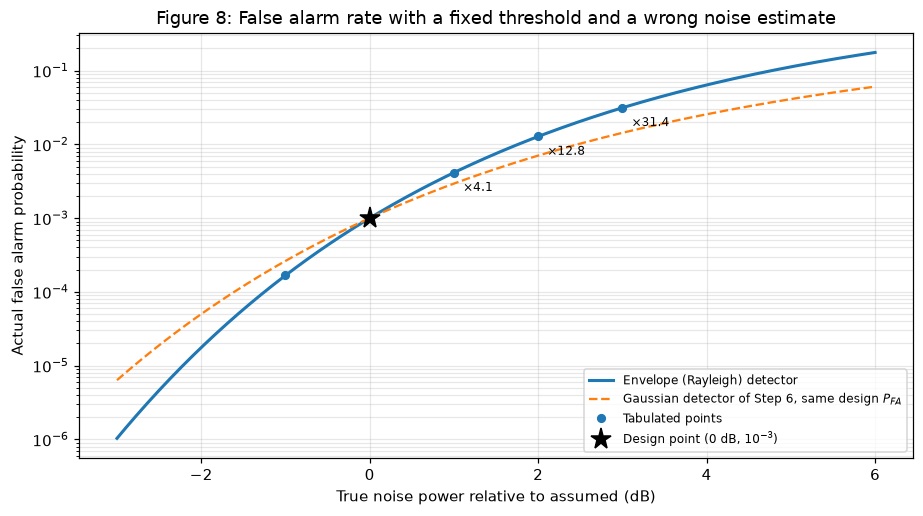

In [26]:
d_grid = np.linspace(-3, 6, 400)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.semilogy(d_grid, pfa_d ** (10 ** (-d_grid / 10)), lw=2, label="Envelope (Rayleigh) detector")
ax.semilogy(d_grid, q_function(q_inverse(pfa_d) / 10 ** (d_grid / 20)), "--",
            label="Gaussian detector of Step 6, same design $P_{FA}$")
ax.semilogy(dB, pfa_act, "o", color="C0", ms=5, label="Tabulated points")
ax.semilogy(0, pfa_d, "k*", ms=14, label="Design point (0 dB, $10^{-3}$)")
for d, p in zip(dB[2:], pfa_act[2:]):
    ax.annotate(f"×{p / pfa_d:.1f}", (d, p), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.set_xlabel("True noise power relative to assumed (dB)")
ax.set_ylabel("Actual false alarm probability")
ax.set_title("Figure 8: False alarm rate with a fixed threshold and a wrong noise estimate")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Interpretation.** On a log scale the actual $P_{FA}$ rises almost linearly in dB: each extra dB of noise multiplies the false alarm rate by about four near the design point, so 1 dB gives ×4.1 and 3 dB gives ×31, matching the check-yourself values. The curve is asymmetric: overestimating the noise by 1 dB lowers $P_{FA}$ to $1.7\times10^{-4}$ (a factor of 6 safer), while underestimating it by 1 dB costs a factor of 4.1, and the cost grows faster with each additional dB. The Gaussian detector of Step 6 (dashed) is hit the same way, slightly less steeply: the local sensitivity $d\ln P_{FA}/d\ln\sigma^2$ is about $T^2/2\sigma^2$, which is exactly $\ln(1/P_{FA}) = 6.9$ for the envelope detector but only about 5.3 for the Gaussian detector, whose threshold for the same $P_{FA}$ is lower (3.09σ vs 3.72σ). The sensitivity is large because a threshold sits in the tail, where probability falls exponentially in $T^2/\sigma^2$, so a small fractional error in $\sigma^2$ becomes a large fractional error in the exponent.

### 7.6 What this means for a fixed-threshold system

A fixed threshold is only correct for one noise power, and real noise floors drift: receiver noise rises with temperature, interference comes and goes, and clutter changes from scan to scan and from one range cell to the next. A 1–3 dB drift, which is ordinary, turns a system designed for $10^{-3}$ into one running at $4\times10^{-3}$ to $3\times10^{-2}$, which means floods of phantom detections that bury the real ones (or, if the noise drops, a detector that is less sensitive than it needs to be). The designer's remedy is to stop assuming the noise and **measure it continuously**: estimate $\hat\sigma^2$ from nearby reference cells that contain only noise and set $T = \alpha\hat\sigma$, which is the constant false alarm rate (CFAR) detector; because $\hat\sigma$ is itself noisy, CFAR costs a little detection probability (the CFAR loss), which shrinks as more reference cells are averaged. Short of that, the designer can calibrate the noise floor periodically, bias the threshold upward by a margin to cover the expected drift (Step 8.5), and confirm detections across several scans so isolated false alarms do not become tracks.

## Step 8: Choosing the operating point

### 8.1 Required SNR for a target $P_D$

From Step 6, $P_{FA} = Q(T/\sigma)$ and $P_D = Q(T/\sigma - A/\sigma)$. Invert both:
$$\frac{T}{\sigma} = Q^{-1}(P_{FA}), \qquad \frac{T}{\sigma} - \frac{A}{\sigma} = Q^{-1}(P_D).$$
Subtract the second from the first:
$$\boxed{\frac{A}{\sigma} = Q^{-1}(P_{FA}) - Q^{-1}(P_D)}, \qquad \text{SNR}_{\text{dB}} = 10\log_{10}\frac{A^2}{\sigma^2} = 20\log_{10}\frac{A}{\sigma}.$$
For $P_D > 0.5$, $Q^{-1}(P_D)$ is negative ($Q^{-1}(0.9) = -1.2816$), so the required $A/\sigma$ is *larger* than the threshold: the signal mean must sit above $T$ for most of the $H_1$ distribution to clear it.

In [27]:
req = lambda pfa, pd: q_inverse(pfa) - q_inverse(pd)
db = lambda a: 20 * np.log10(a)

print(f"Required A/sigma for P_D = 0.9   (Q^-1(0.9) = {q_inverse(0.9):.4f})")
print(f"{'P_FA':>8} {'T/sigma':>9} {'A/sigma':>9} {'SNR (dB)':>9}")
for p in pfa_list:
    print(f"{p:>8.0e} {q_inverse(p):>9.4f} {req(p, 0.9):>9.4f} {db(req(p, 0.9)):>9.2f}")
print(f"\nCost of going from 1e-3 to 1e-6 at P_D = 0.9: {db(req(1e-6, 0.9)) - db(req(1e-3, 0.9)):.2f} dB")

Required A/sigma for P_D = 0.9   (Q^-1(0.9) = -1.2816)
    P_FA   T/sigma   A/sigma  SNR (dB)
   1e-02    2.3263    3.6079     11.15
   1e-03    3.0902    4.3718     12.81
   1e-04    3.7190    5.0006     13.98
   1e-06    4.7534    6.0350     15.61

Cost of going from 1e-3 to 1e-6 at P_D = 0.9: 2.80 dB


#### A check-yourself value I could not match, and why

The handout gives $A/\sigma = 1.81$ (5.15 dB) at $P_{FA} = 10^{-3}$ and $3.47$ (10.81 dB) at $10^{-6}$. Those are exactly $Q^{-1}(P_{FA}) + Q^{-1}(0.9)$, i.e. $3.0902 - 1.2816 = 1.8086$ and $4.7534 - 1.2816 = 3.4718$: the sign of the $Q^{-1}(P_D)$ term is flipped. Three independent checks show the values derived above (4.37 and 6.04) are the correct ones:
1. **Consistency with Step 6.** At $P_{FA} = 10^{-3}$, $A/\sigma = 3$ gives $P_D = 0.46$. $P_D$ increases with $A$, so $P_D = 0.9$ cannot need *less* than 3.
2. **Plugging back in.** $A/\sigma = 1.81$ gives $P_D = Q(3.0902 - 1.8086) = Q(1.2816) = 0.10$, which is $1 - 0.9$, the signature of the sign error.
3. **Monte Carlo**, below.

The handout's qualitative conclusion survives, and is even stronger: three orders of magnitude of false alarm reduction costs 2.80 dB of SNR, not "under 6 dB".

In [28]:
n8 = 1_000_000
print(f"Monte Carlo P_D at P_FA = 1e-3 (T = {q_inverse(1e-3):.4f} sigma), n = {n8:,}")
for label, a in [("derived A/sigma = 4.3718", req(1e-3, 0.9)),
                 ("handout A/sigma = 1.8086", q_inverse(1e-3) + q_inverse(0.9))]:
    est, se = mc_probability(count_exceedances(lambda m, r, a=a: r.standard_normal(m) + a, q_inverse(1e-3), n8, rng8), n8)
    print(f"  {label}: P_D = {est:.4f} +/- {se:.4f}   (analytic {q_function(q_inverse(1e-3) - a):.4f})")

Monte Carlo P_D at P_FA = 1e-3 (T = 3.0902 sigma), n = 1,000,000
  derived A/sigma = 4.3718: P_D = 0.8998 +/- 0.0003   (analytic 0.9000)
  handout A/sigma = 1.8086: P_D = 0.1001 +/- 0.0003   (analytic 0.1000)


### 8.3–8.4 Two systems, two operating points

These per-decision probabilities only mean something once you know how many decisions the system makes per unit time; I assume a smoke alarm samples once every 10 seconds (about $3\times10^6$ decisions per year) and a surveillance radar tests about $10^6$ range–azimuth cells per second.

**Smoke alarm: $P_D = 0.99$, $P_{FA} = 10^{-7}$ per decision.**
- *Where on the ROC:* high and to the left, which means paying for SNR rather than trading one error for the other, because both errors are severe here: a miss can kill, and frequent false alarms lead to the battery being pulled, which turns every future miss into a certainty.
- *$P_D = 0.99$:* a miss is the catastrophic error, and smoke builds over minutes, so 0.99 per 10-second look, repeated, makes the chance of missing a growing fire across a minute negligible ($0.01^6$).
- *$P_{FA} = 10^{-7}$:* at $3\times10^6$ decisions per year this gives about 0.3 noise-driven alarms per year, rare enough that nobody disables the device.
- *Threshold* $T = Q^{-1}(10^{-7})\,\sigma = 5.20\sigma$, *required SNR* $A/\sigma = 7.53$ (17.5 dB). This is affordable because real smoke is a large change in the sensor reading.

**Radar feeding a tracker: $P_D = 0.9$, $P_{FA} = 10^{-6}$ per cell.**
- *Where on the ROC:* very low false alarm probability, moderate detection probability, because the false alarm *rate* is what breaks this system and misses are recoverable.
- *$P_{FA} = 10^{-6}$:* at $10^6$ cells per second it gives about one false alarm per second, which an M-of-N track confirmation rule easily rejects. $10^{-3}$ would give the thousand phantoms per second that make the display useless.
- *$P_D = 0.9$:* a missed scan is recovered on the next one, so pushing to 0.99 would buy little and cost an extra 1.7 dB, which in radar means more power, a bigger antenna, or less range. 0.9 is still high enough to hold tracks.
- *Threshold* $T = 4.75\sigma$, *required SNR* $A/\sigma = 6.04$ (15.6 dB).

In [29]:
ops = {"Smoke alarm": (1e-7, 0.99), "Radar + tracker": (1e-6, 0.9)}
print(f"{'system':<16} {'P_FA':>7} {'P_D':>5} {'T/sigma':>8} {'A/sigma':>8} {'SNR dB':>7}")
for name, (pfa, pd) in ops.items():
    print(f"{name:<16} {pfa:>7.0e} {pd:>5.2f} {q_inverse(pfa):>8.3f} {req(pfa, pd):>8.3f} {db(req(pfa, pd)):>7.2f}")

system              P_FA   P_D  T/sigma  A/sigma  SNR dB
Smoke alarm        1e-07  0.99    5.199    7.526   17.53
Radar + tracker    1e-06  0.90    4.753    6.035   15.61


### Figure 9: Required SNR vs. false alarm probability

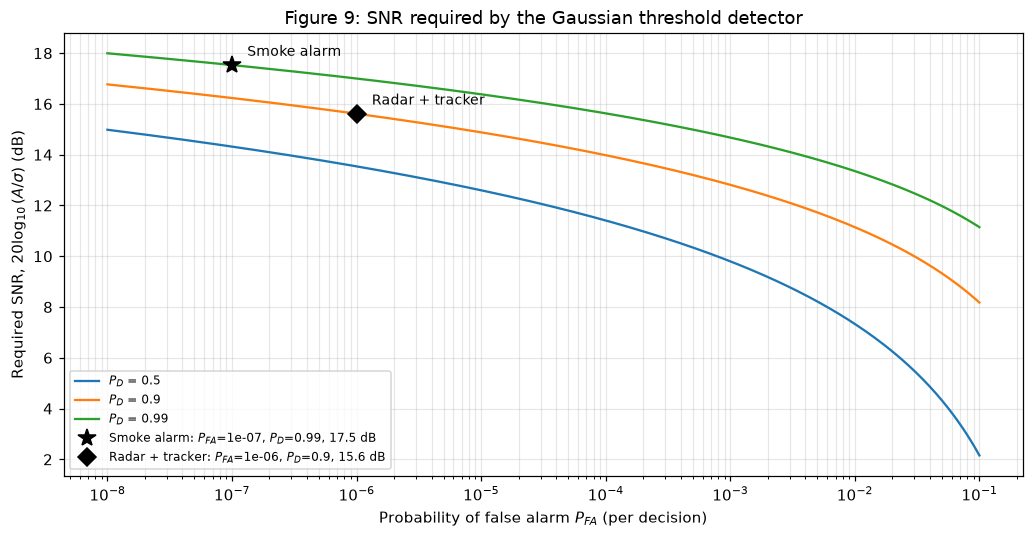

In [30]:
pf = np.logspace(-8, -1, 400)
fig, ax = plt.subplots(figsize=(9.5, 5))
for pd, c in zip([0.5, 0.9, 0.99], ["C0", "C1", "C2"]):
    ax.semilogx(pf, db(req(pf, pd)), color=c, label=f"$P_D$ = {pd}")
for (name, (pfa, pd)), mk in zip(ops.items(), ["*", "D"]):
    s = db(req(pfa, pd))
    ax.plot(pfa, s, "k" + mk, ms=12 if mk == "*" else 8, label=f"{name}: $P_{{FA}}$={pfa:.0e}, $P_D$={pd}, {s:.1f} dB")
    ax.annotate(name, (pfa, s), xytext=(10, 6), textcoords="offset points", fontsize=9)
ax.set_xlabel("Probability of false alarm $P_{FA}$ (per decision)")
ax.set_ylabel("Required SNR, $20\\log_{10}(A/\\sigma)$ (dB)")
ax.set_title("Figure 9: SNR required by the Gaussian threshold detector")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**Interpretation.** Required SNR rises slowly as $P_{FA}$ falls: across seven decades of $P_{FA}$ ($10^{-1}$ to $10^{-8}$) the $P_D = 0.9$ curve climbs only about 8.6 dB, and the last three decades cost under 2 dB, because $Q^{-1}(P_{FA})$ grows like $\sqrt{2\ln(1/P_{FA})}$, so each additional factor of 10 in false alarm reduction is cheaper than the last. The gap between the $P_D$ curves shrinks as $P_{FA}$ falls (from 0.9 to 0.99 it is about 3 dB at $P_{FA} = 10^{-1}$ and 1.3 dB at $10^{-8}$), and it is largest at high $P_{FA}$ where the threshold is low and the $Q^{-1}(P_D)$ term is a larger share of the total. The two operating points sit 1.9 dB apart, and most of that gap comes from the smoke alarm's higher $P_D$, not its lower $P_{FA}$.

### 8.5 Margin for a 1 dB noise error

If the noise power may be up to 1 dB higher than assumed, set the threshold for the worst case, $\sigma_{\max} = 10^{1/20}\sigma = 1.122\sigma$, which raises $T$ by 12.2 percent. The cost is computed below at the *nominal* noise level: the $P_D$ lost if the SNR budget stays the same, and the extra SNR needed to restore the target $P_D$.

In [31]:
k = 10 ** (1 / 20)
print(f"{'system':<16} {'T nominal':>10} {'T w/ margin':>12} {'P_FA @ +1dB, no margin':>23} {'P_D w/ margin':>14} {'extra SNR':>10}")
for name, (pfa, pd) in ops.items():
    T0 = q_inverse(pfa); T1 = k * T0; A = req(pfa, pd)
    pfa_no_margin = q_function(T0 / k)
    pd_margin = q_function(T1 - A)
    extra = db(T1 - q_inverse(pd)) - db(A)
    print(f"{name:<16} {T0:>10.3f} {T1:>12.3f} {pfa_no_margin:>13.2e} (x{pfa_no_margin / pfa:>4.1f}) {pd_margin:>14.3f} {extra:>8.2f} dB")

system            T nominal  T w/ margin  P_FA @ +1dB, no margin  P_D w/ margin  extra SNR
Smoke alarm           5.199        5.834      1.79e-06 (x17.9)          0.955     0.70 dB
Radar + tracker       4.753        5.333      1.14e-05 (x11.4)          0.759     0.80 dB


**Recommendation with margin.** Without margin, a 1 dB noise error multiplies the false alarm rate by about 18 for the smoke alarm and 11 for the radar (the Gaussian-detector version of Step 7's ×4.1, larger here because these designs sit deeper in the tail, where the sensitivity $T^2/2\sigma^2$ is larger). With the threshold raised by 1 dB (×1.122), $P_{FA}$ stays at or below its design value for any noise power up to 1 dB high. The price, at nominal noise, is a $P_D$ drop from 0.99 to about 0.95 for the smoke alarm and from 0.90 to about 0.76 for the radar if the SNR budget is unchanged, or equivalently 0.7–0.8 dB of extra SNR to keep the original $P_D$. I would take the margin in both systems and pay for it in SNR: less than 1 dB of SNR to protect against a ×10 false alarm rate is a good trade, and for the smoke alarm it is the trade that keeps the battery in.

### 8.6 The question to answer before committing

**How much does the noise power actually vary in deployment, and how many false alarms per unit time will the user tolerate?** That one question sets both the margin (Step 8.5) and the per-decision $P_{FA}$ (since false alarms per year = $P_{FA}$ × decisions per year). It has to be answered by the people who own the requirement and the environment: for the smoke alarm, the product owner working from the UL 217 nuisance-alarm requirements and field return data; for the radar, the customer and the tracker/display team, who know how many false tracks per second the operators and processors can absorb, together with whoever has measured the site's clutter and interference.

## Bonus A: Characteristic functions

The characteristic function is $\phi_X(\omega) = E[e^{j\omega X}] = \int f(x)e^{j\omega x}dx$, the Fourier transform of the density. For independent $X, Y$:
$$\phi_{X+Y}(\omega) = E[e^{j\omega X}e^{j\omega Y}] = E[e^{j\omega X}]\,E[e^{j\omega Y}] = \phi_X(\omega)\phi_Y(\omega),$$
because the expectation of a product of independent variables factors. Since the density of $X+Y$ is the convolution $f_X * f_Y$, this is the convolution theorem.

I use $U \sim \mathcal U[0,1]$ and $E \sim$ Exponential(1). Closed forms for comparison: $\phi_U(\omega) = \frac{e^{j\omega}-1}{j\omega}$ and $\phi_E(\omega) = \frac{1}{1-j\omega}$. The density of $S = U + E$ follows from the convolution integral:
$$f_S(s) = \int_0^{\min(s,1)} e^{-(s-u)}\,du = \begin{cases}1 - e^{-s}, & 0 \le s < 1\\ (e-1)\,e^{-s}, & s \ge 1.\end{cases}$$

In [32]:
dx, n = 0.002, 2**14                       # grid [0, 32.77); exponential tail e^-32 is negligible
x = np.arange(n) * dx
fU = np.where(x < 1, 1.0, 0.0); fU[int(round(1 / dx))] = 0.5   # density on the grid
fE = np.exp(-x)
# Trapezoid-rule weights: half weight on the first grid point (and at the uniform's
# jump, already set above). Without them every integral is off by about dx * f(0).
wU, wE = fU.copy(), fE.copy(); wU[0] *= 0.5; wE[0] *= 0.5

# CF numerically, by direct quadrature E[e^{jwX}] = sum f(x) e^{jwx} dx, on a few frequencies
w = np.array([0.5, 1.0, 2.0, 5.0])
phi = lambda f: (f[None, :] * np.exp(1j * w[:, None] * x[None, :])).sum(axis=1) * dx
phiU, phiE = phi(wU), phi(wE)
print("Numerical CF vs closed form (|difference|):")
print("  w    |phiU num - exact|   |phiE num - exact|")
for wi, a, b in zip(w, phiU, phiE):
    print(f"  {wi:<4} {abs(a - (np.exp(1j * wi) - 1) / (1j * wi)):>18.1e} {abs(b - 1 / (1 - 1j * wi)):>20.1e}")

# Empirical CF of the sum from samples vs the product
Ns = 1_000_000
S = rngA.random(Ns) + rngA.exponential(1.0, Ns)
phiS_emp = np.exp(1j * w[:, None] * S[None, :Ns // 10]).mean(axis=1)   # 1e5 samples, SE ~ 0.003
print("\nphi_{U+E}(w): empirical (1e5 samples) vs phi_U * phi_E")
for wi, a, b in zip(w, phiS_emp, phiU * phiE):
    print(f"  w = {wi:<4} empirical {a.real:+.4f}{a.imag:+.4f}j   product {b.real:+.4f}{b.imag:+.4f}j   |diff| {abs(a - b):.4f}")

Numerical CF vs closed form (|difference|):
  w    |phiU num - exact|   |phiE num - exact|
  0.5             8.2e-08              3.7e-07
  1.0             3.2e-07              4.7e-07
  2.0             1.1e-06              7.5e-07
  5.0             2.0e-06              1.7e-06

phi_{U+E}(w): empirical (1e5 samples) vs phi_U * phi_E
  w = 0.5  empirical +0.6693+0.5800j   product +0.6691+0.5794j   |diff| 0.0006
  w = 1.0  empirical +0.1904+0.6526j   product +0.1909+0.6506j   |diff| 0.0021
  w = 2.0  empirical -0.1964+0.3228j   product -0.1923+0.3235j   |diff| 0.0042
  w = 5.0  empirical -0.0367-0.0326j   product -0.0349-0.0314j   |diff| 0.0021


max |CF route - direct convolution| = 2.2e-16
max |CF route - exact density|      = 5.0e-04  (grid step 0.002)
KS of samples of U+E vs integrated CF-route density: 0.0009  (crit 0.0014)
time: CF/FFT route 4.07 ms, direct convolution 186.5 ms  (x46), grid n = 16,384


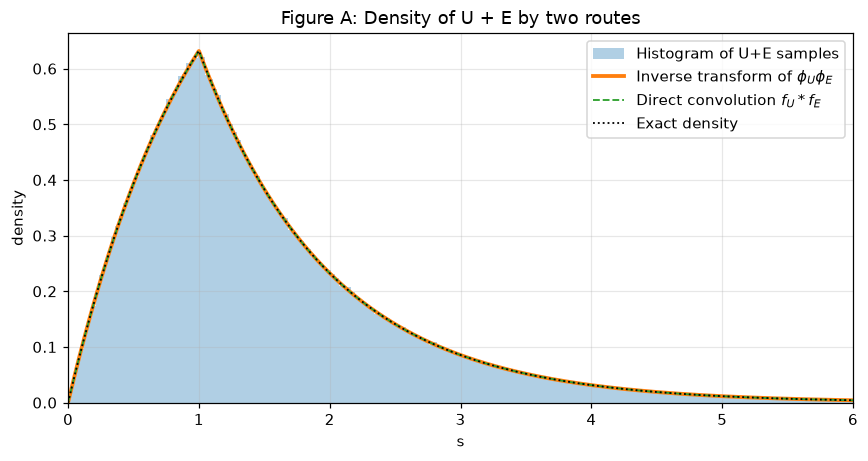

In [33]:
f_S_exact = np.where(x < 1, 1 - np.exp(-x), (np.e - 1) * np.exp(-x))

# Route 1: characteristic functions. FFT each density (zero-padded to 2n so the
# circular convolution has room and does not wrap), multiply, inverse FFT.
t0 = time.perf_counter()
for _ in range(20):
    F = np.fft.rfft(wU, 2 * n) * np.fft.rfft(wE, 2 * n)
    f_S_cf = np.fft.irfft(F, 2 * n)[:n] * dx
t_cf = (time.perf_counter() - t0) / 20

# Route 2: direct numerical convolution, O(n^2)
t0 = time.perf_counter()
f_S_conv = np.convolve(wU, wE)[:n] * dx
t_conv = time.perf_counter() - t0

F_S_cf = np.concatenate([[0.0], np.cumsum((f_S_cf[1:] + f_S_cf[:-1]) / 2) * dx])   # trapezoid CDF
print(f"max |CF route - direct convolution| = {np.max(np.abs(f_S_cf - f_S_conv)):.1e}")
print(f"max |CF route - exact density|      = {np.max(np.abs(f_S_cf - f_S_exact)):.1e}  (grid step {dx})")
print(f"KS of samples of U+E vs integrated CF-route density: "
      f"{ks_statistic(S, lambda s: np.interp(s, x, F_S_cf)):.4f}  (crit {ks_critical(Ns):.4f})")
print(f"time: CF/FFT route {t_cf * 1e3:.2f} ms, direct convolution {t_conv * 1e3:.1f} ms  "
      f"(x{t_conv / t_cf:.0f}), grid n = {n:,}")

fig, ax = plt.subplots(figsize=(8, 4.3))
ax.hist(S, bins=200, range=(0, 6), density=True, alpha=0.35, label="Histogram of U+E samples")
ax.plot(x, f_S_cf, lw=2.5, label="Inverse transform of $\\phi_U\\phi_E$")
ax.plot(x, f_S_conv, "--", lw=1.2, label="Direct convolution $f_U * f_E$")
ax.plot(x, f_S_exact, ":", color="k", lw=1.2, label="Exact density")
ax.set_xlim(0, 6); ax.set_xlabel("s"); ax.set_ylabel("density")
ax.set_title("Figure A: Density of U + E by two routes")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation.** The numerically computed characteristic functions match the closed forms to the accuracy of the grid, the empirical characteristic function of $U + E$ matches the product $\phi_U\phi_E$ within its sampling error (about 0.003 for $10^5$ samples), and the density recovered from the product agrees with direct convolution to round-off and with the exact density to within the grid discretization error (largest at the jump at $s = 1$, where the exact density has a kink); integrated to a CDF, it passes the KS test against $10^6$ samples of $U+E$. Getting there required trapezoid weights on the grid: plain Riemann sums put every integral off by about $\Delta x\, f(0) = 0.002$, which a million-sample KS test is sensitive enough to detect. The two routes compute the same thing; the difference is cost. Direct convolution of two $n$-point densities takes $n$ multiply-adds for each of $n$ output points, $O(n^2)$, while the characteristic-function route takes three FFTs at $O(n\log n)$ each plus an $O(n)$ pointwise product, so at $n = 2^{14}$ it is orders of magnitude faster (timing above), and the advantage grows with $n$. It grows again for sums of many variables: the density of a sum of $k$ independent terms is one product of $k$ transforms and one inverse FFT, rather than $k-1$ successive convolutions.

## Bonus B: A distribution with no mean

### Density of $Z = X/Y$

Let $X, Y \sim \mathcal N(0,1)$ be independent. Condition on $Y = y$: then $Z = X/y$, a scaled Gaussian, with density $|y|\,\varphi(zy)$ (change of variables $x = zy$, $dx = |y|\,dz$). Average over $y$:
$$f_Z(z) = \int_{-\infty}^{\infty} |y|\,\varphi(zy)\,\varphi(y)\,dy = \frac{1}{2\pi}\int_{-\infty}^\infty |y|\,e^{-y^2(1+z^2)/2}\,dy = \frac{2}{2\pi}\int_0^\infty y\,e^{-y^2(1+z^2)/2}\,dy.$$
With $\int_0^\infty y\,e^{-ay^2/2}\,dy = 1/a$ and $a = 1+z^2$:
$$f_Z(z) = \frac{1}{\pi}\cdot\frac{1}{1+z^2}, \qquad F_Z(z) = \frac12 + \frac{\arctan z}{\pi}.$$
This is the standard Cauchy distribution. Its tails fall like $z^{-2}$, so $\int |z|\,f_Z(z)\,dz \propto \int dz/z$ diverges logarithmically: **the mean does not exist**, and neither does any higher moment.

KS of X/Y vs Cauchy CDF: 0.00053  (crit 0.00136 at N = 1,000,000)

        N  sample mean  sample median  median SE pi/(2 sqrt N)
    1,000       0.1849         0.0371                   0.0497
   10,000      -0.5625        -0.0384                   0.0157
  100,000      -0.2108        -0.0046                   0.0050
1,000,000       0.7591        -0.0001                   0.0016


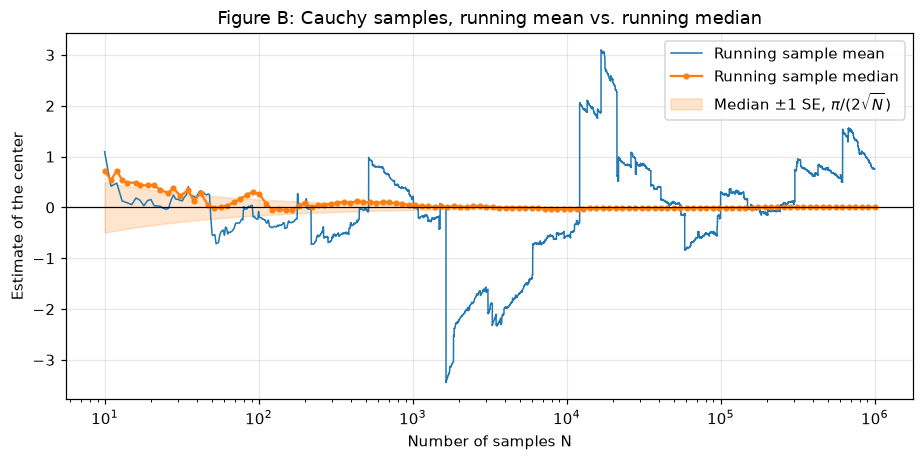

In [34]:
NB = 1_000_000
Zc = rngB.standard_normal(NB) / rngB.standard_normal(NB)
ksB = ks_statistic(Zc, lambda z: 0.5 + np.arctan(z) / np.pi)
print(f"KS of X/Y vs Cauchy CDF: {ksB:.5f}  (crit {ks_critical(NB):.5f} at N = {NB:,})")

run_mean = np.cumsum(Zc) / np.arange(1, NB + 1)
print(f"\n{'N':>9} {'sample mean':>12} {'sample median':>14} {'median SE pi/(2 sqrt N)':>24}")
for m in [10**3, 10**4, 10**5, 10**6]:
    print(f"{m:>9,} {run_mean[m-1]:>12.4f} {np.median(Zc[:m]):>14.4f} {np.pi / (2 * np.sqrt(m)):>24.4f}")

idxB = np.unique(np.logspace(1, 6, 120).astype(int))
run_med = np.array([np.median(Zc[:m]) for m in idxB])
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.semilogx(np.arange(1, NB + 1)[9:], run_mean[9:], lw=1, label="Running sample mean")
ax.semilogx(idxB, run_med, "o-", ms=3, label="Running sample median")
ax.fill_between(idxB, -np.pi / (2 * np.sqrt(idxB)), np.pi / (2 * np.sqrt(idxB)), alpha=0.2,
                color="C1", label=r"Median $\pm$1 SE, $\pi/(2\sqrt{N})$")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Number of samples N"); ax.set_ylabel("Estimate of the center")
ax.set_title("Figure B: Cauchy samples, running mean vs. running median")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretation.** The KS statistic confirms that $X/Y$ is Cauchy. The running median closes in on zero inside its $\pi/(2\sqrt N)$ band, while the running mean keeps lurching by large amounts whenever an extreme sample arrives (the near-zero denominators produce values in the thousands) and does not settle at any $N$.

**Why $10^6$ samples are no better than one.** Using Bonus A: the Cauchy characteristic function is $\phi(\omega) = e^{-|\omega|}$, so the sum of $N$ independent samples has $\phi^N = e^{-N|\omega|}$, and the sample mean $\bar Z = S_N/N$ has $\phi_{\bar Z}(\omega) = e^{-N|\omega/N|} = e^{-|\omega|}$, which is exactly the characteristic function of a single sample. The average of a million Cauchy samples has the same distribution as one sample: averaging adds no information, because the largest term is always comparable to the whole sum.

**What to use instead.** The **sample median** (or a trimmed mean that discards the extreme tails before averaging). Its error shrinks like $\pi/(2\sqrt N)$, it is unaffected by how wild the largest samples are, and it depends only on the existence of a density at the center. For noise this heavy-tailed, any detector or estimator built on sums and averages, including the threshold-on-a-mean designs above, needs to be rebuilt on order statistics.

### Presentation Link
https://youtu.be/eDz7nud8FkA 

In [35]:
print(f"Total notebook runtime: {time.time() - T_START:.1f} s")

Total notebook runtime: 42.5 s
